# Step 3: Communities, Cores and Bridges

**Sections:** 3.0 network projections, 3.1 Louvain and modularity, 3.2 weighted sensitivity, 3.3 k-core decomposition, 3.4 bridging roles across 100 runs, 3.5 relationship with degree, and 3.6 exports and validation. Airport-removal losses and H3 testing belong to Step 7.

**Why this step matters.** H2 asks whether observed resilience differs from degree-preserving randomized networks, and H3 asks whether bridging positions matter beyond degree. Both need a defensible description of how each airline's airports group together.

**Representations used here**

| Name | Graph | Weights | Role |
|---|---|---|---|
| `graphs` | Directed | `frequency` | Original network, never modified |
| `D_binary` | Directed | None | Primary topology for the null-model and resilience steps |
| `U_binary` | Undirected | None | **Primary** projection for communities |
| `U_weighted` | Undirected | `weight` = sum of flights in both directions | **Supplementary** sensitivity analysis |

## Section 3.0: Network projections

In [1]:
import hashlib
import os
import platform
from itertools import combinations
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import scipy
import sklearn
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import adjusted_rand_score

# Local execution is enabled only when this environment variable is set.
# It is not set on Colab, so Colab always uses the Google Drive path below.
LOCAL_PROJECT_ROOT = os.environ.get("NETWORK_ANALYSIS_LOCAL_ROOT")

if LOCAL_PROJECT_ROOT:
    BASE = Path(LOCAL_PROJECT_ROOT) / "Data"
else:
    from google.colab import drive
    drive.mount("/content/drive")

    # Notice the trailing space after 'Network Analysis '
    BASE = Path("/content/drive/MyDrive/Network Analysis /Data")

RAW = BASE / "raw"
PROCESSED = BASE / "Processed"

PROJECT_ROOT = BASE.parent
RESULTS = PROJECT_ROOT / "Results"
FIGURES = RESULTS / "Figures"
TABLES = RESULTS / "Tables"

FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

AIRLINES = {
    "AA": "American Airlines",
    "DL": "Delta Air Lines",
    "WN": "Southwest Airlines"
}

# Community-detection settings used for every airline
LOUVAIN_RESOLUTION = 1.0
LOUVAIN_SEEDS = list(range(100))

print("Processed directory exists:", PROCESSED.exists())
print("Runs per airline:", len(LOUVAIN_SEEDS), "| resolution:", LOUVAIN_RESOLUTION)

Processed directory exists: True
Runs per airline: 100 | resolution: 1.0


**Load the original networks.** The node and edge files are read exactly as in Notebook 02. A fingerprint of each network is stored here and checked again at the end of the notebook, which proves the originals were not altered.

In [2]:
def network_fingerprint(G):
    """Hash of every node and every (source, target, frequency) edge."""
    payload = repr((
        sorted(G.nodes()),
        sorted((u, v, d["frequency"]) for u, v, d in G.edges(data=True))
    ))
    return hashlib.sha256(payload.encode("utf-8")).hexdigest()


graphs = {}
airport_tables = {}

for airline in AIRLINES:
    nodes = pd.read_csv(PROCESSED / f"{airline}_nodes.csv")
    edges = pd.read_csv(PROCESSED / f"{airline}_edges.csv")

    G = nx.DiGraph(airline=airline)

    for row in nodes.itertuples(index=False):
        G.add_node(int(row.airport_id), code=row.code, city=row.city, state=row.state)

    for row in edges.itertuples(index=False):
        G.add_edge(int(row.source), int(row.target), frequency=float(row.frequency))

    assert G.number_of_nodes() == len(nodes)
    assert G.number_of_edges() == len(edges)

    graphs[airline] = G
    airport_tables[airline] = nodes

original_fingerprints = {a: network_fingerprint(G) for a, G in graphs.items()}

for airline, G in graphs.items():
    print(f"{airline}: {G.number_of_nodes()} airports, {G.number_of_edges()} directed routes")

AA: 230 airports, 1808 directed routes
DL: 212 airports, 1506 directed routes
WN: 104 airports, 1792 directed routes


**Build the projections.** Each projection is built from a sorted edge list, because Louvain's result for a given seed depends on node order. `nx.Graph(G)` is deliberately not used for weights: on a reciprocal network it keeps the frequency of only one direction. Here, both directions are summed explicitly.

In [3]:
def to_directed_binary(G):
    D = nx.DiGraph(airline=G.graph["airline"])
    D.add_nodes_from(sorted(G.nodes()))
    D.add_edges_from(sorted(G.edges()))
    return D


def to_undirected_binary(G):
    U = nx.Graph(airline=G.graph["airline"])
    U.add_nodes_from(sorted(G.nodes()))
    U.add_edges_from(sorted({(min(u, v), max(u, v)) for u, v in G.edges()}))
    return U


def to_undirected_weighted(G):
    totals = {}

    for u, v, data in G.edges(data=True):
        pair = (min(u, v), max(u, v))
        totals[pair] = totals.get(pair, 0.0) + data["frequency"]

    W = nx.Graph(airline=G.graph["airline"])
    W.add_nodes_from(sorted(G.nodes()))

    for (u, v), weight in sorted(totals.items()):
        W.add_edge(u, v, weight=weight)

    return W


D_binary = {a: to_directed_binary(G) for a, G in graphs.items()}
U_binary = {a: to_undirected_binary(G) for a, G in graphs.items()}
U_weighted = {a: to_undirected_weighted(G) for a, G in graphs.items()}

print("Projections built for:", ", ".join(U_binary))

Projections built for: AA, DL, WN


**Validate the projections** against the original networks and the Step 1 and Step 2 exports.

In [4]:
network_summary = pd.read_csv(PROCESSED / "network_summary.csv").set_index("Airline")
step2_summary = pd.read_csv(TABLES / "02_final_network_comparison.csv").set_index("Airline")

validation_rows = []

for airline, G in graphs.items():
    D, U, W = D_binary[airline], U_binary[airline], U_weighted[airline]
    n, m = G.number_of_nodes(), G.number_of_edges()
    total_flights = sum(d["frequency"] for _, _, d in G.edges(data=True))

    # Node sets and edge counts
    assert set(D) == set(U) == set(W) == set(G)
    assert D.number_of_edges() == m
    assert set(D.edges()) == set(G.edges())
    assert U.number_of_edges() == m / 2
    assert set(U.edges()) == set(W.edges())

    # Simple graphs, no leaked weights in binary projections
    for H in (D, U, W):
        assert nx.number_of_selfloops(H) == 0
    assert all(len(d) == 0 for _, _, d in D.edges(data=True))
    assert all(len(d) == 0 for _, _, d in U.edges(data=True))

    # Reciprocity and degree consistency
    assert nx.reciprocity(D) == 1.0
    assert all(D.in_degree(v) == D.out_degree(v) == U.degree(v) for v in G)
    assert nx.is_connected(U)

    # Each undirected weight equals the explicit two-direction sum
    assert all(
        d["weight"] == G[u][v]["frequency"] + G[v][u]["frequency"]
        for u, v, d in W.edges(data=True)
    )
    assert np.isclose(W.size(weight="weight"), total_flights)

    # Agreement with earlier validated exports
    assert n == step2_summary.loc[airline, "Airports"]
    assert m == step2_summary.loc[airline, "Directed routes"]
    assert np.isclose(total_flights, network_summary.loc[airline, "Total scheduled flights"])

    unequal_pairs = sum(
        G[u][v]["frequency"] != G[v][u]["frequency"] for u, v in U.edges()
    )

    validation_rows.append({
        "Airline": airline,
        "Airports": n,
        "Directed binary edges": D.number_of_edges(),
        "Undirected edges": U.number_of_edges(),
        "Reciprocity": nx.reciprocity(D),
        "Total scheduled flights": total_flights,
        "Sum of undirected weights": W.size(weight="weight"),
        "Pairs with unequal directional frequency": unequal_pairs,
        "Undirected graph connected": nx.is_connected(U)
    })

projection_validation = pd.DataFrame(validation_rows)
display(projection_validation)

projection_validation.to_csv(TABLES / "03_projection_validation.csv", index=False)
print("PASS: All projections agree with the original networks.")

,Airline,Airports,Directed binary edges,Undirected edges,Reciprocity,Total scheduled flights,Sum of undirected weights,Pairs with unequal directional frequency,Undirected graph connected
0,AA,230,1808,904,1.0,514206.0,514206.0,299,True
1,DL,212,1506,753,1.0,418790.0,418790.0,104,True
2,WN,104,1792,896,1.0,359789.0,359789.0,209,True


PASS: All projections agree with the original networks.


## Section 3.1: Louvain community detection and modularity (primary, binary)

Louvain is a randomized heuristic, so one run can give one of several good partitions. We therefore run it with 100 recorded seeds, calculate modularity for every run, and keep the highest-modularity partition as the primary result. Ties are resolved by the lowest seed.

Agreement between partitions is measured with the **Adjusted Rand Index (ARI)**: 1 means identical groupings, and values near 0 mean agreement no better than chance. ARI does not depend on community numbering.

In [5]:
def canonical_labels(communities, node_order):
    """Stable labels: community 0 is the largest, ties by smallest airport ID."""
    ordered = sorted((sorted(c) for c in communities), key=lambda c: (-len(c), c[0]))
    mapping = {node: label for label, community in enumerate(ordered) for node in community}
    return np.array([mapping[node] for node in node_order], dtype=int)


def run_louvain_ensemble(graph, airline, weight):
    node_order = sorted(graph.nodes())
    run_rows, labels = [], []

    for seed in LOUVAIN_SEEDS:
        communities = nx.community.louvain_communities(
            graph, weight=weight, resolution=LOUVAIN_RESOLUTION, seed=seed
        )
        modularity = nx.community.modularity(
            graph, communities, weight=weight, resolution=LOUVAIN_RESOLUTION
        )
        label_vector = canonical_labels(communities, node_order)
        sizes = np.bincount(label_vector)

        labels.append(label_vector)
        run_rows.append({
            "Airline": airline,
            "Seed": seed,
            "Modularity": modularity,
            "Communities": len(communities),
            "Largest community": int(sizes.max()),
            "Smallest community": int(sizes.min())
        })

    runs = pd.DataFrame(run_rows)
    labels = np.vstack(labels)
    q = runs["Modularity"].to_numpy()
    best_index = int(np.flatnonzero(q >= q.max() - 1e-12)[0])

    return runs, labels, best_index, node_order


def pairwise_ari(labels):
    return np.array([
        adjusted_rand_score(labels[i], labels[j])
        for i, j in combinations(range(len(labels)), 2)
    ])


def independent_modularity(graph, label_vector, node_order, weight):
    """Newman modularity written out directly, as a check on NetworkX."""
    label_of = dict(zip(node_order, label_vector))
    k = len(set(label_vector))
    internal, degree_sum = np.zeros(k), np.zeros(k)
    m = 0.0

    for u, v, data in graph.edges(data=True):
        w = data[weight] if weight else 1.0
        m += w
        degree_sum[label_of[u]] += w
        degree_sum[label_of[v]] += w
        if label_of[u] == label_of[v]:
            internal[label_of[u]] += w

    return float(np.sum(internal / m - (degree_sum / (2 * m)) ** 2))


def summarize_ensemble(airline, graph, runs, labels, best_index, node_order, weight):
    q = runs["Modularity"]
    best_labels = labels[best_index]
    sizes = np.sort(np.bincount(best_labels))[::-1]

    pair_ari = pairwise_ari(labels)
    to_best = np.array([adjusted_rand_score(best_labels, row) for row in labels])
    unique_partitions = len({tuple(row) for row in labels})
    runs_matching_best = int(sum(np.array_equal(row, best_labels) for row in labels))

    check = independent_modularity(graph, best_labels, node_order, weight)
    assert np.isclose(check, q.iloc[best_index]), "Modularity check failed"
    assert np.bincount(best_labels).sum() == graph.number_of_nodes()

    return {
        "Airline": airline,
        "Airports": graph.number_of_nodes(),
        "Best seed": int(runs["Seed"].iloc[best_index]),
        "Best modularity": float(q.iloc[best_index]),
        "Mean modularity": float(q.mean()),
        "SD modularity": float(q.std(ddof=1)),
        "Min modularity": float(q.min()),
        "Communities (best)": len(sizes),
        "Communities min across runs": int(runs["Communities"].min()),
        "Communities median across runs": float(runs["Communities"].median()),
        "Communities max across runs": int(runs["Communities"].max()),
        "Community sizes (best)": ", ".join(map(str, sizes)),
        "Largest community share (%)": float(100 * sizes[0] / sizes.sum()),
        "Distinct partitions in 100 runs": unique_partitions,
        "Runs identical to best": runs_matching_best,
        "Pairwise ARI mean": float(pair_ari.mean()),
        "Pairwise ARI median": float(np.median(pair_ari)),
        "Pairwise ARI min": float(pair_ari.min()),
        "Pairwise ARI 2.5%": float(np.percentile(pair_ari, 2.5)),
        "Pairwise ARI 97.5%": float(np.percentile(pair_ari, 97.5)),
        "ARI to best mean": float(to_best.mean()),
        "ARI to best min": float(to_best.min())
    }, pair_ari


# ARI sanity checks: identical up to relabeling gives 1
_example = np.array([0, 0, 1, 1, 2, 2])
assert np.isclose(adjusted_rand_score(_example, (_example + 1) % 3), 1.0)
print("ARI sanity check passed.")

ARI sanity check passed.


In [6]:
binary_runs, binary_labels, binary_best, binary_summary, binary_pair_ari = {}, {}, {}, [], {}
node_orders = {}

for airline in AIRLINES:
    runs, labels, best_index, node_order = run_louvain_ensemble(U_binary[airline], airline, None)
    summary, pair_ari = summarize_ensemble(
        airline, U_binary[airline], runs, labels, best_index, node_order, None
    )

    binary_runs[airline] = runs
    binary_labels[airline] = labels
    binary_best[airline] = labels[best_index]
    binary_summary.append(summary)
    binary_pair_ari[airline] = pair_ari
    node_orders[airline] = node_order

binary_summary_df = pd.DataFrame(binary_summary)

pd.concat(binary_runs.values(), ignore_index=True).to_csv(
    TABLES / "03_louvain_binary_runs.csv", index=False
)
binary_summary_df.to_csv(TABLES / "03_louvain_binary_summary.csv", index=False)

display(binary_summary_df.set_index("Airline").T)

Airline,AA,DL,WN
Airports,230,212,104
Best seed,72,27,96
Best modularity,0.21174,0.226523,0.190161
Mean modularity,0.199183,0.217065,0.184639
SD modularity,0.004146,0.00239,0.003376
Min modularity,0.185906,0.209194,0.173512
Communities (best),5,5,3
Communities min across runs,3,4,3
Communities median across runs,5.0,6.0,3.0
Communities max across runs,5,8,4


**Describe the primary communities.** The airports with the most routes are listed so each community can be read in airline terms. Degree here is a label only and no bridging quantity is calculated.

In [7]:
def airport_community_table(airline, labels_by_node, column):
    table = airport_tables[airline].rename(columns={
        "airport_id": "AirportID", "code": "Code", "city": "City", "state": "State"
    }).copy()
    table.insert(0, "Airline", airline)
    table[column] = table["AirportID"].map(labels_by_node)
    assert table[column].notna().all()
    table[column] = table[column].astype(int)
    return table


def community_profile(airline, table, column, graph):
    degree = dict(graph.degree())
    frame = table.assign(Degree=table["AirportID"].map(degree))
    rows = []

    for label, members in frame.groupby(column):
        top = members.sort_values(["Degree", "Code"], ascending=[False, True]).head(5)
        rows.append({
            "Airline": airline,
            "Community": int(label),
            "Airports": len(members),
            "Share of airports (%)": 100 * len(members) / len(frame),
            "Top airports by routes": ", ".join(f"{c} ({d})" for c, d in zip(top["Code"], top["Degree"]))
        })

    return rows


binary_tables, profile_rows = [], []

for airline in AIRLINES:
    labels_by_node = dict(zip(node_orders[airline], binary_best[airline]))
    table = airport_community_table(airline, labels_by_node, "Community")
    binary_tables.append(table)
    profile_rows.extend(community_profile(airline, table, "Community", U_binary[airline]))

airport_communities_binary = pd.concat(binary_tables, ignore_index=True)
binary_profile_df = pd.DataFrame(profile_rows)

airport_communities_binary.to_csv(TABLES / "03_airport_communities_binary.csv", index=False)
binary_profile_df.to_csv(TABLES / "03_community_profiles_binary.csv", index=False)

with pd.option_context("display.max_colwidth", None):
    display(binary_profile_df.round(1))

,Airline,Community,Airports,Share of airports (%),Top airports by routes
0,AA,0,86,37.4,"DFW (182), PHX (92), LAX (45), ATL (8), OKC (8)"
1,AA,1,51,22.2,"PHL (88), DCA (86), LGA (58), BOS (24), CMH (11)"
2,AA,2,49,21.3,"CLT (136), MIA (75), JAX (7), MKE (7), BDL (6)"
3,AA,3,29,12.6,"ORD (136), AUS (11), AGS (10), ASE (5), BZN (4)"
4,AA,4,15,6.5,"JFK (24), SDF (15), RDU (13), BNA (12), PIT (12)"
5,DL,0,79,37.3,"MSP (118), DTW (100), JFK (57), BOS (54), ORD (8)"
6,DL,1,57,26.9,"ATL (154), LGA (75), IAH (6), MSN (5), STL (5)"
7,DL,2,54,25.5,"SLC (89), SEA (47), LAX (44), LAS (15), MCI (10)"
8,DL,3,13,6.1,"RDU (21), CVG (18), DCA (17), MCO (16), BNA (13)"
9,DL,4,9,4.2,"AUS (23), IND (10), MSY (9), MEM (8), JAX (7)"


### Interpretation of the primary binary results

**Organization.** The selected partitions have modularity Q = 0.212 (AA, 5 communities), 0.227 (DL, 5 communities) and 0.190 (WN, 3 communities). Reading the largest airports in each community, the groups are mostly organized around one or more major hubs: for example, DFW with PHX and LAX for AA, and ATL with LGA for DL. WN divides into three large groups led by MDW/BNA/BWI, DEN/LAS/PHX and DAL/HOU/STL. These labels describe only the largest airports in each community.

**Strength of structure.** These modularity values are modest. They cannot yet be called higher or lower than expected, because that requires the degree-preserving null ensembles from Step 4. The differences between airlines are small and the networks differ in size, so they should not be ranked on Q alone.

**Stability.** Agreement across seeds is moderate: the mean pairwise ARI is 0.698 (AA), 0.724 (DL) and 0.634 (WN). Almost every run produced a different partition (100, 99 and 83 distinct partitions in 100 runs), and each selected partition was found by exactly one seed. The selected partition is therefore the best one *found in 100 seeds*, and it may not be the global optimum. Its mean ARI to the other runs is 0.613 (AA), 0.623 (DL) and 0.635 (WN), so for AA and DL it agrees with the other runs less than typical pairs of runs agree with each other.

**Implication.** The broad grouping around hubs recurs, but the assignment of individual airports, especially small ones, is uncertain. Any later measure based on a single partition should be checked for sensitivity to the partition used.

## Section 3.2: Weighted sensitivity analysis (supplementary)

This section repeats the same 100 seeds on `U_weighted`, where an edge's weight is the total number of scheduled flights in both directions. **The binary results remain the primary findings.**

Louvain varies from seed to seed, so a low ARI between two single partitions could reflect randomness rather than flight frequency. To separate those, we compare all 100 binary runs with all 100 weighted runs and set that agreement against the agreement seen within each ensemble.

In [8]:
weighted_runs, weighted_labels, weighted_best, weighted_summary, weighted_pair_ari = {}, {}, {}, [], {}

for airline in AIRLINES:
    runs, labels, best_index, node_order = run_louvain_ensemble(U_weighted[airline], airline, "weight")
    assert node_order == node_orders[airline]
    summary, pair_ari = summarize_ensemble(
        airline, U_weighted[airline], runs, labels, best_index, node_order, "weight"
    )

    weighted_runs[airline] = runs
    weighted_labels[airline] = labels
    weighted_best[airline] = labels[best_index]
    weighted_summary.append(summary)
    weighted_pair_ari[airline] = pair_ari

weighted_summary_df = pd.DataFrame(weighted_summary)

pd.concat(weighted_runs.values(), ignore_index=True).to_csv(
    TABLES / "03_louvain_weighted_runs.csv", index=False
)
weighted_summary_df.to_csv(TABLES / "03_louvain_weighted_summary.csv", index=False)

display(weighted_summary_df.set_index("Airline").T)

Airline,AA,DL,WN
Airports,230,212,104
Best seed,3,0,8
Best modularity,0.240811,0.266251,0.266941
Mean modularity,0.232718,0.264952,0.264867
SD modularity,0.003952,0.003039,0.001977
Min modularity,0.222272,0.252355,0.247243
Communities (best),4,5,4
Communities min across runs,3,4,3
Communities median across runs,4.0,5.0,4.0
Communities max across runs,5,5,4


In [9]:
def communities_from_labels(label_vector, node_order):
    groups = {}
    for node, label in zip(node_order, label_vector):
        groups.setdefault(int(label), set()).add(node)
    return list(groups.values())


def match_weighted_to_binary(binary, weighted):
    """Match community labels by largest overlap; return weighted labels in binary numbering."""
    overlap = pd.crosstab(pd.Series(binary, name="b"), pd.Series(weighted, name="w"))
    row, col = linear_sum_assignment(-overlap.to_numpy())
    mapping = {overlap.columns[c]: overlap.index[r] for r, c in zip(row, col)}
    next_label = int(max(binary)) + 1

    for label in overlap.columns:
        if label not in mapping:
            mapping[label] = next_label
            next_label += 1

    return np.array([mapping[w] for w in weighted])


comparison_rows, weighted_tables, weighted_profile_rows = [], [], []

for airline in AIRLINES:
    order = node_orders[airline]
    b_runs, w_runs = binary_labels[airline], weighted_labels[airline]
    b_best, w_best = binary_best[airline], weighted_best[airline]

    cross = np.array([
        adjusted_rand_score(b, w) for b in b_runs for w in w_runs
    ])
    same_seed = np.array([
        adjusted_rand_score(b, w) for b, w in zip(b_runs, w_runs)
    ])

    b_comm = communities_from_labels(b_best, order)
    w_comm = communities_from_labels(w_best, order)
    U, W = U_binary[airline], U_weighted[airline]

    matched = match_weighted_to_binary(b_best, w_best)
    moved = matched != b_best

    table = airport_community_table(airline, dict(zip(order, w_best)), "Community_weighted")
    table["Community_binary"] = table["AirportID"].map(dict(zip(order, b_best))).astype(int)
    table["Community_weighted_matched_to_binary"] = table["AirportID"].map(dict(zip(order, matched))).astype(int)
    table["Reassigned"] = table["AirportID"].map(dict(zip(order, moved))).astype(bool)
    weighted_tables.append(table)
    weighted_profile_rows.extend(
        community_profile(airline, table, "Community_weighted", W)
    )

    degree = dict(U.degree())
    hubs = sorted(order, key=lambda v: (-degree[v], U.number_of_nodes()))[:10]
    code_of = dict(zip(table["AirportID"], table["Code"]))
    moved_of = dict(zip(order, moved))

    comparison_rows.append({
        "Airline": airline,
        "ARI best binary vs best weighted": adjusted_rand_score(b_best, w_best),
        "Binary within-ensemble ARI mean": float(binary_pair_ari[airline].mean()),
        "Weighted within-ensemble ARI mean": float(weighted_pair_ari[airline].mean()),
        "Cross ARI mean (100 x 100)": float(cross.mean()),
        "Cross ARI 2.5%": float(np.percentile(cross, 2.5)),
        "Cross ARI 97.5%": float(np.percentile(cross, 97.5)),
        "Same-seed ARI mean": float(same_seed.mean()),
        "Communities binary": len(b_comm),
        "Communities weighted": len(w_comm),
        "Q binary partition on binary graph": nx.community.modularity(U, b_comm, weight=None),
        "Q weighted partition on binary graph": nx.community.modularity(U, w_comm, weight=None),
        "Q weighted partition on weighted graph": nx.community.modularity(W, w_comm, weight="weight"),
        "Q binary partition on weighted graph": nx.community.modularity(W, b_comm, weight="weight"),
        "Airports reassigned after matching": int(moved.sum()),
        "Airports reassigned (%)": 100 * float(moved.mean()),
        "Top-10 route hubs reassigned": ", ".join(code_of[v] for v in hubs if moved_of[v]) or "none"
    })

comparison_df = pd.DataFrame(comparison_rows)
airport_communities_weighted = pd.concat(weighted_tables, ignore_index=True)
weighted_profile_df = pd.DataFrame(weighted_profile_rows)

comparison_df.to_csv(TABLES / "03_binary_vs_weighted_comparison.csv", index=False)
airport_communities_weighted.to_csv(TABLES / "03_airport_communities_weighted.csv", index=False)
weighted_profile_df.to_csv(TABLES / "03_community_profiles_weighted.csv", index=False)

display(comparison_df.set_index("Airline").T)

with pd.option_context("display.max_colwidth", None):
    display(weighted_profile_df.round(1))

Airline,AA,DL,WN
ARI best binary vs best weighted,0.450666,0.456468,0.529181
Binary within-ensemble ARI mean,0.697617,0.724312,0.633949
Weighted within-ensemble ARI mean,0.880401,0.937882,0.886143
Cross ARI mean (100 x 100),0.372112,0.436437,0.433289
Cross ARI 2.5%,0.322365,0.371802,0.312715
Cross ARI 97.5%,0.435082,0.478032,0.576615
Same-seed ARI mean,0.371595,0.437986,0.435044
Communities binary,5,5,3
Communities weighted,4,5,4
Q binary partition on binary graph,0.21174,0.226523,0.190161


,Airline,Community,Airports,Share of airports (%),Top airports by routes
0,AA,0,104,45.2,"DFW (182), PHX (92), LAX (45), AUS (11), LAS (9)"
1,AA,1,50,21.7,"CLT (136), AGS (10), ILM (8), AVL (7), GSO (7)"
2,AA,2,42,18.3,"PHL (88), DCA (86), MIA (75), LGA (58), BOS (24)"
3,AA,3,34,14.8,"ORD (136), STL (10), DSM (8), DTW (8), GRR (8)"
4,DL,0,75,35.4,"ATL (154), MSY (9), MEM (8), SDF (8), JAX (7)"
5,DL,1,55,25.9,"SLC (89), SEA (47), LAX (44), LAS (15), DEN (9)"
6,DL,2,50,23.6,"MSP (118), DTW (100), MCI (10), EWR (7), GRB (7)"
7,DL,3,28,13.2,"LGA (75), JFK (57), BOS (54), RDU (21), CVG (18)"
8,DL,4,4,1.9,"AUS (23), HRL (2), MAF (1), MFE (1)"
9,WN,0,47,45.2,"MDW (75), BNA (73), BWI (67), STL (57), MCO (51)"


**Figures.** The first shows run-to-run variability of the primary analysis. The second compares community sizes between the two projections.

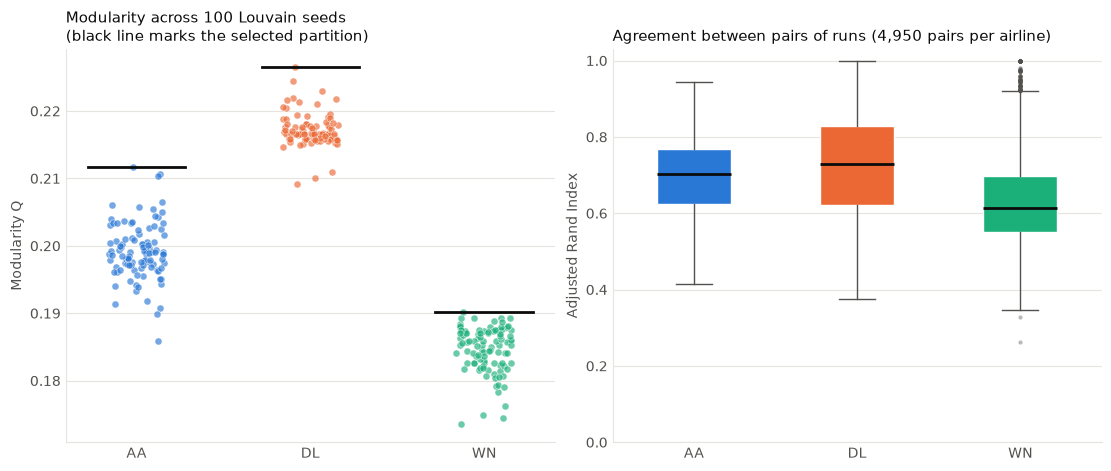

In [10]:
INK = "#0b0b0b"
MUTED = "#52514e"
GRID = "#e5e4df"
AIRLINE_COLORS = {"AA": "#2a78d6", "DL": "#eb6834", "WN": "#1baf7a"}
PROJECTION_COLORS = {"Binary (primary)": "#6250d6", "Weighted (supplementary)": "#eda100"}


def style_axis(ax):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=MUTED, length=0)
    ax.yaxis.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)


rng = np.random.default_rng(0)  # only used to spread overlapping points horizontally
fig, (ax_q, ax_ari) = plt.subplots(1, 2, figsize=(11, 4.6), constrained_layout=True)

for position, airline in enumerate(AIRLINES):
    q = binary_runs[airline]["Modularity"].to_numpy()
    jitter = rng.uniform(-0.16, 0.16, len(q))
    ax_q.scatter(position + jitter, q, s=26, color=AIRLINE_COLORS[airline], alpha=0.65,
                 edgecolor="white", linewidth=0.5, label=airline)
    ax_q.plot([position - 0.28, position + 0.28], [q.max()] * 2, color=INK, linewidth=2)

ax_q.set_xticks(range(len(AIRLINES)), list(AIRLINES))
ax_q.set_ylabel("Modularity Q", color=MUTED)
ax_q.set_title("Modularity across 100 Louvain seeds\n(black line marks the selected partition)",
               color=INK, fontsize=11, loc="left")
style_axis(ax_q)

parts = ax_ari.boxplot(
    [binary_pair_ari[a] for a in AIRLINES],
    tick_labels=list(AIRLINES), widths=0.45, patch_artist=True,
    medianprops={"color": INK, "linewidth": 2}, flierprops={"marker": "o", "markersize": 3,
    "markerfacecolor": MUTED, "markeredgecolor": "none", "alpha": 0.4},
    whiskerprops={"color": MUTED}, capprops={"color": MUTED}
)
for patch, airline in zip(parts["boxes"], AIRLINES):
    patch.set_facecolor(AIRLINE_COLORS[airline])
    patch.set_edgecolor("white")

ax_ari.set_ylim(0, 1.03)
ax_ari.set_ylabel("Adjusted Rand Index", color=MUTED)
ax_ari.set_title("Agreement between pairs of runs (4,950 pairs per airline)",
                 color=INK, fontsize=11, loc="left")
style_axis(ax_ari)

fig.savefig(FIGURES / "03_louvain_stability_binary.png", dpi=300, bbox_inches="tight")
plt.show()

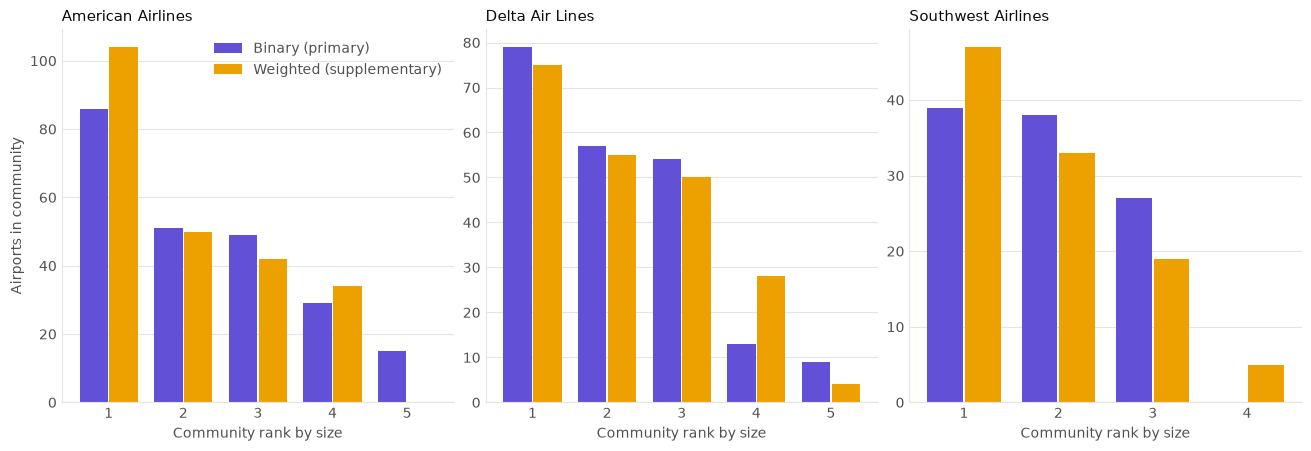

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), constrained_layout=True)

for ax, airline in zip(axes, AIRLINES):
    binary_sizes = np.sort(np.bincount(binary_best[airline]))[::-1]
    weighted_sizes = np.sort(np.bincount(weighted_best[airline]))[::-1]
    max_len = max(len(binary_sizes), len(weighted_sizes))
    x = np.arange(1, max_len + 1)
    width = 0.38

    b = np.pad(binary_sizes, (0, max_len - len(binary_sizes)))
    w = np.pad(weighted_sizes, (0, max_len - len(weighted_sizes)))

    ax.bar(x - width / 2 - 0.01, b, width, color=PROJECTION_COLORS["Binary (primary)"], label="Binary (primary)")
    ax.bar(x + width / 2 + 0.01, w, width, color=PROJECTION_COLORS["Weighted (supplementary)"], label="Weighted (supplementary)")
    ax.set_xticks(x)
    ax.set_xlabel("Community rank by size", color=MUTED)
    ax.set_title(AIRLINES[airline], color=INK, fontsize=11, loc="left")
    style_axis(ax)

axes[0].set_ylabel("Airports in community", color=MUTED)
axes[0].legend(frameon=False, labelcolor=MUTED)

fig.savefig(FIGURES / "03_community_sizes_binary_vs_weighted.png", dpi=300, bbox_inches="tight")
plt.show()

**Final integrity checks** confirm the original networks are unchanged and record the software versions, because a given Louvain seed can produce a different partition under a different NetworkX version.

In [12]:
for airline, G in graphs.items():
    assert network_fingerprint(G) == original_fingerprints[airline], f"{airline} original network changed"

labels_binary = pd.read_csv(TABLES / "03_airport_communities_binary.csv")
centralities = pd.read_csv(TABLES / "02_airport_centralities.csv")
merged = centralities.merge(
    labels_binary[["Airline", "AirportID", "Community"]],
    on=["Airline", "AirportID"], how="outer", validate="one_to_one", indicator=True
)
assert (merged["_merge"] == "both").all()

run_metadata = pd.DataFrame([{
    "Python": platform.python_version(),
    "NetworkX": nx.__version__,
    "NumPy": np.__version__,
    "pandas": pd.__version__,
    "SciPy": scipy.__version__,
    "scikit-learn": sklearn.__version__,
    "Louvain resolution": LOUVAIN_RESOLUTION,
    "Seeds": f"{LOUVAIN_SEEDS[0]}-{LOUVAIN_SEEDS[-1]}"
}])
run_metadata.to_csv(TABLES / "03_run_metadata.csv", index=False)
display(run_metadata)

print("PASS: Original directed weighted networks are unchanged.")
print("PASS: Every airport in the Step 2 table has exactly one community label.")

,Python,NetworkX,NumPy,pandas,SciPy,scikit-learn,Louvain resolution,Seeds
0,3.14.5,3.6.1,2.4.6,3.0.5,1.18.1,1.9.0,1.0,0-99


PASS: Original directed weighted networks are unchanged.
PASS: Every airport in the Step 2 table has exactly one community label.


### Interpretation of the weighted sensitivity analysis (supplementary)

**Does flight frequency change the community organization? Yes.** The selected binary and weighted partitions agree only moderately (ARI = 0.451 for AA, 0.456 for DL and 0.529 for WN). Across all 100 x 100 pairs of runs, mean agreement is 0.372, 0.436 and 0.433. That is clearly lower than agreement within either ensemble (binary 0.698, 0.724, 0.634; weighted 0.880, 0.938, 0.886), so the difference is not explained by seed-to-seed noise alone. The 95% ranges of binary-within and cross-projection ARI do not overlap for AA or DL, but they do overlap for WN.

**What changes.** After matching communities by overlap, 75 AA airports (32.6%), 59 DL airports (27.8%) and 24 WN airports (23.1%) change community. Among each airline's ten highest-degree hubs, MIA moves for AA, LGA, JFK and BOS move for DL, and STL moves for WN. Weighting gives Delta a distinct LGA/JFK/BOS-led community and gives Southwest a separate five-airport Hawaii community (HNL, OGG, KOA, LIH, ITO). The major groupings around DFW, ATL, SLC/SEA/LAX, DEN/LAS/PHX and MDW/BNA/BWI persist in both projections.

**Stability and modularity.** Weighted runs are considerably more stable than binary runs, because flight frequencies reduce the number of near-equivalent partitions. Weighted Q is higher in these runs (0.241, 0.266, 0.267), but Q values on different graphs are not directly comparable, so this does not show that the weighted partition is better.

**Decision.** The binary partition remains the primary result, as agreed: it describes the same route topology used by the null-model and resilience analyses. The weighted result shows that community membership depends meaningfully on whether route frequency is considered, and this should be stated as a limitation of community-based interpretation.

## Stored partitions for Sections 3.3 to 3.6

The across-run bridging analysis needs each airport's community label in every Louvain run. These cells save all 100 binary and all 100 weighted partitions created in Sections 3.1 and 3.2. They then check that modularity recomputed from the saved labels matches the per-run results. No new Louvain settings are introduced.

In [13]:
def labels_to_frame(labels_by_airline):
    frames = []

    for airline, labels in labels_by_airline.items():
        frame = pd.DataFrame(
            labels.T,
            columns=[f"Seed_{seed}" for seed in LOUVAIN_SEEDS]
        )
        frame.insert(0, "AirportID", node_orders[airline])
        frame.insert(0, "Airline", airline)
        frames.append(frame)

    return pd.concat(frames, ignore_index=True)


labels_to_frame(binary_labels).to_csv(TABLES / "03_louvain_run_labels_binary.csv", index=False)
labels_to_frame(weighted_labels).to_csv(TABLES / "03_louvain_run_labels_weighted.csv", index=False)

saved_binary = pd.read_csv(TABLES / "03_louvain_binary_runs.csv")
saved_weighted = pd.read_csv(TABLES / "03_louvain_weighted_runs.csv")

for airline in AIRLINES:
    order = node_orders[airline]

    for graph, labels, saved, weight in [
        (U_binary[airline], binary_labels[airline], saved_binary, None),
        (U_weighted[airline], weighted_labels[airline], saved_weighted, "weight"),
    ]:
        expected = saved.loc[saved["Airline"] == airline, "Modularity"].to_numpy()
        recomputed = np.array([
            nx.community.modularity(graph, communities_from_labels(row, order), weight=weight)
            for row in labels
        ])
        assert labels.shape == (100, graph.number_of_nodes())
        assert np.allclose(recomputed, expected, atol=1e-12)

print("PASS: Saved labels reproduce the modularity of all 200 runs per airline.")

PASS: Saved labels reproduce the modularity of all 200 runs per airline.


## Section 3.3: K-core decomposition

A **k-core** is the largest subnetwork in which every airport has at least k connections inside that subnetwork. An airport's **core number** is the highest k for which it remains in such a subnetwork. Core numbers show whether an airline has a densely interlinked centre, which degree alone cannot show: an airport can have many routes that lead only to small spokes.

Core numbers use the primary binary undirected projection, `U_binary`, so flight frequency plays no role. The projection is lossless for route topology because every route is reciprocal.

In [14]:
core_numbers = {}
kcore_summary_rows, kcore_member_rows, kcore_shell_rows = [], [], []

for airline in AIRLINES:
    U = U_binary[airline]
    core = nx.core_number(U)
    core_numbers[airline] = core

    code_of = dict(zip(airport_tables[airline]["airport_id"], airport_tables[airline]["code"]))
    degree = dict(U.degree())
    n = U.number_of_nodes()
    k_max = max(core.values())
    innermost = sorted((v for v in U if core[v] == k_max), key=lambda v: (-degree[v], code_of[v]))
    inner_graph = U.subgraph(innermost)
    top_hubs = sorted(U, key=lambda v: (-degree[v], code_of[v]))[:10]

    assert set(innermost) == set(nx.k_core(U, k=k_max).nodes())

    kcore_summary_rows.append({
        "Airline": airline,
        "Airports": n,
        "Maximum core number": k_max,
        "Maximum core / (N-1)": k_max / (n - 1),
        "Innermost core size": len(innermost),
        "Innermost core share (%)": 100 * len(innermost) / n,
        "Innermost core density": nx.density(inner_graph),
        "Innermost core connected": nx.is_connected(inner_graph),
        "Mean core number": float(np.mean(list(core.values()))),
        "Median core number": float(np.median(list(core.values()))),
        "Core number 1 airports (%)": 100 * sum(c == 1 for c in core.values()) / n,
        "Top-10 degree airports in innermost core": sum(core[v] == k_max for v in top_hubs),
        "Innermost core members": ", ".join(code_of[v] for v in innermost)
    })

    for v in innermost:
        kcore_member_rows.append({
            "Airline": airline, "AirportID": v, "Code": code_of[v],
            "Core number": k_max, "Degree": degree[v]
        })

    for k, count in sorted(pd.Series(core).value_counts().items()):
        kcore_shell_rows.append({"Airline": airline, "Core number": int(k), "Airports": int(count)})

kcore_summary_df = pd.DataFrame(kcore_summary_rows)
kcore_members_df = pd.DataFrame(kcore_member_rows)
kcore_shells_df = pd.DataFrame(kcore_shell_rows)

kcore_summary_df.to_csv(TABLES / "03_kcore_summary.csv", index=False)
kcore_members_df.to_csv(TABLES / "03_kcore_innermost_members.csv", index=False)
kcore_shells_df.to_csv(TABLES / "03_kcore_shells.csv", index=False)

with pd.option_context("display.max_colwidth", None):
    display(kcore_summary_df.set_index("Airline").T.round(3))

Airline,AA,DL,WN
Airports,230,212,104
Maximum core number,11,12,15
Maximum core / (N-1),0.048035,0.056872,0.145631
Innermost core size,17,17,28
Innermost core share (%),7.391304,8.018868,26.923077
Innermost core density,0.867647,0.897059,0.777778
Innermost core connected,True,True,True
Mean core number,4.234783,3.938679,9.836538
Median core number,3.0,3.0,9.5
Core number 1 airports (%),23.913043,33.018868,1.923077


### Interpretation of the k-core results

Maximum core numbers are 11 (AA), 12 (DL) and 15 (WN). The innermost cores contain 17 AA airports (7.4%), 17 DL airports (8.0%) and 28 WN airports (26.9%). Each airline's ten highest-degree airports are all in its innermost core. WN's innermost core is proportionally much larger, which is consistent with its denser and less concentrated route structure.

**Coreness is almost redundant with degree for AA and DL.** Among eligible airports, the Spearman correlation between degree and core number is 0.9995 (AA), 0.9986 (DL) and 0.978 (WN). Core number equals degree for 93.0% of AA airports, 92.0% of DL airports and 63.5% of WN airports. This is expected in a hub-and-spoke structure: a small airport connected mainly to well-connected hubs keeps all of its links during core pruning, so its core number equals its degree. Coreness should not be presented as independent evidence beyond degree for AA and DL.

## Section 3.4: Bridging roles across 100 Louvain runs

**Participation coefficient (binary).** For airport i in one partition, P_i = 1 - sum over communities s of (k_is / k_i)^2, where k_is is the number of i's routes to community s and k_i is its degree. P_i is 0 when all routes stay in one community and grows as they spread evenly across several.

**Inter-community edge fraction.** The share of airport i's routes that go to a different community from its own.

**Why 100 runs.** Section 3.1 showed that no run reliably reproduces the selected partition. Each airport's measures are therefore calculated separately for each run and summarized across runs. The spread shown here is **algorithmic variation across Louvain runs. These are not confidence intervals** and do not express sampling uncertainty.

**Eligibility.** Airport-level bridging comparisons use airports with degree at least 2. A degree-1 airport has all of its routes going to one community, so its P is mechanically 0 in every partition. Degree-1 airports remain in the network and in every exported table, marked as ineligible, but they receive no bridging rank.

**Ranking rules.** Airports are ranked among eligible airports only, with rank 1 being the highest P. Average rank across runs uses tied-average ranks. "Top 10" uses minimum ranks, so airports tied at position 10 are all counted and no arbitrary tie-break favours one airport.

**Comparing across airlines.** The largest possible P depends on the number of communities (1 - 1/C). It therefore varies between airlines and between runs, so P values should be compared mainly within an airline.

In [15]:
ELIGIBLE_MIN_DEGREE = 2
TOP_K = 10


def participation_and_external(adjacency, labels):
    """Return P_i and the inter-community share of each airport's total tie weight."""
    n = adjacency.shape[0]
    ties_by_community = adjacency @ np.eye(labels.max() + 1)[labels]
    strength = adjacency.sum(axis=1)
    shares = ties_by_community / strength[:, None]
    participation = np.maximum(1 - (shares ** 2).sum(axis=1), 0.0)
    external = 1 - ties_by_community[np.arange(n), labels] / strength
    return participation, external


def summarize_runs(matrix, prefix):
    return pd.DataFrame({
        f"{prefix} mean": matrix.mean(axis=0),
        f"{prefix} SD": matrix.std(axis=0, ddof=1),
        f"{prefix} median": np.median(matrix, axis=0),
        f"{prefix} 2.5%": np.percentile(matrix, 2.5, axis=0),
        f"{prefix} 97.5%": np.percentile(matrix, 97.5, axis=0)
    })


def bridging_table(airline, graph, label_matrix, weight, prefix, include_external):
    order = node_orders[airline]
    adjacency = nx.to_numpy_array(graph, nodelist=order, weight=weight, dtype=float)
    results = [participation_and_external(adjacency, row) for row in label_matrix]
    participation = np.vstack([r[0] for r in results])
    external = np.vstack([r[1] for r in results])

    binary_degree = np.array([U_binary[airline].degree(v) for v in order])
    eligible = binary_degree >= ELIGIBLE_MIN_DEGREE

    frame_of_runs = pd.DataFrame(participation[:, eligible])
    average_ranks = frame_of_runs.rank(axis=1, ascending=False, method="average").to_numpy()
    minimum_ranks = frame_of_runs.rank(axis=1, ascending=False, method="min").to_numpy()
    in_top = minimum_ranks <= TOP_K

    table = pd.DataFrame({"Airline": airline, "AirportID": order, "Degree": binary_degree, "Eligible (degree >= 2)": eligible})
    table = pd.concat([table, summarize_runs(participation, prefix)], axis=1)
    if include_external:
        table = pd.concat([table, summarize_runs(external, "Inter-community fraction")], axis=1)

    rank_col = f"{prefix} average rank across runs"
    table[rank_col] = np.nan
    table.loc[eligible, rank_col] = average_ranks.mean(axis=0)
    table["Runs in top 10"] = np.nan
    table.loc[eligible, "Runs in top 10"] = in_top.sum(axis=0)
    table["Runs in top 10 (%)"] = 100 * table["Runs in top 10"] / len(label_matrix)
    table[f"Rank by mean {prefix}"] = table.loc[eligible, f"{prefix} mean"].rank(ascending=False, method="min")

    return table, participation, external, eligible, in_top


bridging_frames, P_runs, external_runs, eligible_masks, top_sets = [], {}, {}, {}, {}

for airline in AIRLINES:
    table, participation, external, eligible, in_top = bridging_table(
        airline, U_binary[airline], binary_labels[airline], None, "Participation", True
    )
    best = binary_best[airline]
    adjacency = nx.to_numpy_array(U_binary[airline], nodelist=node_orders[airline], weight=None, dtype=float)
    table["Participation in best-modularity partition (descriptive)"] = participation_and_external(adjacency, best)[0]

    bridging_frames.append(table)
    P_runs[airline] = participation
    external_runs[airline] = external
    eligible_masks[airline] = eligible
    top_sets[airline] = in_top

bridging_binary = pd.concat(bridging_frames, ignore_index=True)

codes = pd.concat([
    t.rename(columns={"airport_id": "AirportID", "code": "Code"})[["AirportID", "Code"]].assign(Airline=a)
    for a, t in airport_tables.items()
])
bridging_binary = bridging_binary.merge(codes, on=["Airline", "AirportID"], how="left", validate="one_to_one")

stability_rows, network_rows = [], []

for airline in AIRLINES:
    participation = P_runs[airline]
    eligible = eligible_masks[airline]
    in_top = top_sets[airline]
    counts = in_top.sum(axis=0)
    labels = binary_labels[airline]
    adjacency = nx.to_numpy_array(U_binary[airline], nodelist=node_orders[airline], weight=None, dtype=float)

    ranks = pd.DataFrame(participation[:, eligible]).rank(axis=1).to_numpy()
    rank_corr = np.corrcoef(ranks)[np.triu_indices(len(labels), k=1)]

    per_run_fraction = np.array([
        ((row[:, None] != row[None, :]) * adjacency).sum() / adjacency.sum()
        for row in labels
    ])

    for seed, fraction, row in zip(LOUVAIN_SEEDS, per_run_fraction, labels):
        network_rows.append({
            "Airline": airline, "Seed": seed,
            "Communities": int(row.max() + 1),
            "Inter-community route fraction": fraction
        })

    stability_rows.append({
        "Airline": airline,
        "Eligible airports": int(eligible.sum()),
        "Excluded airports (degree < 2)": int((~eligible).sum()),
        "Median airport SD of participation": float(np.median(participation[:, eligible].std(axis=0, ddof=1))),
        "Between-run Spearman of participation, mean": float(rank_corr.mean()),
        "Between-run Spearman of participation, min": float(rank_corr.min()),
        "Mean top-10 set size (includes ties)": float(in_top.sum(axis=1).mean()),
        "Max top-10 set size (includes ties)": int(in_top.sum(axis=1).max()),
        "Airports ever in top 10": int((counts > 0).sum()),
        "Airports in top 10 in at least 50% of runs": int((counts >= 50).sum()),
        "Airports in top 10 in at least 90% of runs": int((counts >= 90).sum()),
        "Airports in top 10 in all runs": int((counts == 100).sum()),
        "Network inter-community route fraction, mean": float(per_run_fraction.mean()),
        "Network inter-community route fraction, SD": float(per_run_fraction.std(ddof=1)),
        "Network inter-community route fraction, 2.5%": float(np.percentile(per_run_fraction, 2.5)),
        "Network inter-community route fraction, 97.5%": float(np.percentile(per_run_fraction, 97.5))
    })

bridging_stability = pd.DataFrame(stability_rows)
network_external_runs = pd.DataFrame(network_rows)

bridging_stability.to_csv(TABLES / "03_bridging_stability_binary.csv", index=False)
network_external_runs.to_csv(TABLES / "03_network_intercommunity_fraction_runs.csv", index=False)

display(bridging_stability.set_index("Airline").T.round(3))

Airline,AA,DL,WN
Eligible airports,175.000,142.000,102.000
Excluded airports (degree < 2),55.000,70.000,2.000
Median airport SD of participation,0.037,0.039,0.071
"Between-run Spearman of participation, mean",0.924,0.918,0.820
"Between-run Spearman of participation, min",0.633,0.602,0.196
Mean top-10 set size (includes ties),11.330,10.580,10.090
Max top-10 set size (includes ties),18.000,19.000,11.000
Airports ever in top 10,54.000,37.000,47.000
Airports in top 10 in at least 50% of runs,10.000,6.000,7.000
Airports in top 10 in at least 90% of runs,0.000,0.000,0.000


**Top bridging airports and comparison with directed betweenness.** Betweenness is reused from the Step 2 table and is not recalculated.

In [16]:
centralities = pd.read_csv(TABLES / "02_airport_centralities.csv")

airport_metrics = bridging_binary.merge(
    centralities.drop(columns=["Code"]),
    on=["Airline", "AirportID"],
    how="left",
    validate="one_to_one"
)
assert airport_metrics["Betweenness"].notna().all()

display_columns = [
    "Airline", "Code", "Degree", "Betweenness",
    "Participation mean", "Participation SD",
    "Participation 2.5%", "Participation 97.5%",
    "Participation average rank across runs",
    "Runs in top 10", "Runs in top 10 (%)"
]

top_rows, betweenness_rows, betweenness_comparison = [], [], []

for airline in AIRLINES:
    table = airport_metrics[(airport_metrics["Airline"] == airline) & airport_metrics["Eligible (degree >= 2)"]].copy()
    table["Betweenness rank"] = table["Betweenness"].rank(ascending=False, method="min")

    top_bridges = table.nsmallest(TOP_K, "Rank by mean Participation")
    top_betweenness = table.nlargest(TOP_K, "Betweenness")
    overlap = sorted(set(top_bridges["Code"]) & set(top_betweenness["Code"]))

    top_rows.append(top_bridges.assign(**{"Betweenness rank": top_bridges["Betweenness rank"]}))
    betweenness_rows.append(top_betweenness)

    betweenness_comparison.append({
        "Airline": airline,
        "Eligible airports": len(table),
        "Spearman mean participation vs betweenness": table["Participation mean"].corr(table["Betweenness"], method="spearman"),
        "Spearman mean inter-community fraction vs betweenness": table["Inter-community fraction mean"].corr(table["Betweenness"], method="spearman"),
        "Top-10 overlap (bridging vs betweenness)": len(overlap),
        "Airports in both top 10s": ", ".join(overlap) or "none",
        "Top-10 bridges with zero betweenness": int((top_bridges["Betweenness"] == 0).sum()),
        "Mean participation rank of top-10 betweenness airports": float(top_betweenness["Rank by mean Participation"].mean())
    })

top_bridging_df = pd.concat(top_rows, ignore_index=True)
top_betweenness_df = pd.concat(betweenness_rows, ignore_index=True)
betweenness_comparison_df = pd.DataFrame(betweenness_comparison)

top_bridging_df[display_columns + ["Rank by mean Participation", "Betweenness rank"]].to_csv(
    TABLES / "03_top_bridging_airports.csv", index=False
)
top_betweenness_df[display_columns + ["Rank by mean Participation", "Betweenness rank"]].to_csv(
    TABLES / "03_top_betweenness_airports_bridging.csv", index=False
)
betweenness_comparison_df.to_csv(TABLES / "03_bridging_vs_betweenness.csv", index=False)

display(top_bridging_df[display_columns + ["Betweenness rank"]].round(3))
display(betweenness_comparison_df.set_index("Airline").T.round(3))

,Airline,Code,Degree,Betweenness,Participation mean,Participation SD,Participation 2.5%,Participation 97.5%,Participation average rank across runs,Runs in top 10,Runs in top 10 (%),Betweenness rank
0,AA,PIT,12,0.000,0.742,0.033,0.687,0.778,7.420,72.0,72.0,16.0
1,AA,BNA,12,0.000,0.741,0.035,0.653,0.778,8.090,69.0,69.0,14.0
2,AA,RDU,13,0.000,0.740,0.039,0.668,0.769,9.040,64.0,64.0,15.0
3,AA,SDF,15,0.000,0.737,0.033,0.662,0.782,10.385,72.0,72.0,13.0
4,AA,IAH,8,0.000,0.732,0.025,0.671,0.750,10.445,80.0,80.0,39.0
5,AA,MIA,75,0.022,0.722,0.047,0.636,0.770,17.040,61.0,61.0,7.0
6,AA,STT,6,0.000,0.717,0.047,0.611,0.778,14.505,80.0,80.0,23.0
7,AA,LAS,9,0.000,0.717,0.029,0.667,0.765,14.000,28.0,28.0,23.0
8,AA,SFO,8,0.000,0.716,0.026,0.656,0.750,15.345,35.0,35.0,23.0
9,AA,ORD,136,0.185,0.713,0.029,0.670,0.767,15.050,34.0,34.0,3.0


Airline,AA,DL,WN
Eligible airports,175,142,102
Spearman mean participation vs betweenness,0.487809,0.569027,0.339594
Spearman mean inter-community fraction vs betweenness,0.408221,0.488941,0.218501
Top-10 overlap (bridging vs betweenness),2,0,5
Airports in both top 10s,"MIA, ORD",none,"DAL, DEN, HOU, LAS, STL"
Top-10 bridges with zero betweenness,1,1,2
Mean participation rank of top-10 betweenness airports,61.6,36.9,14.5


**Weighted participation (supplementary sensitivity analysis).** This uses the 100 weighted partitions from Section 3.2 and the flight-weighted form of the same formula, with k replaced by the summed two-direction flights. These scores are kept in a separate table and are never averaged or combined with the binary scores. Binary bridging remains primary.

In [17]:
weighted_frames, weighted_comparison = [], []

for airline in AIRLINES:
    table, *_ = bridging_table(
        airline, U_weighted[airline], weighted_labels[airline], "weight", "Weighted participation", False
    )
    weighted_frames.append(table)

bridging_weighted = pd.concat(weighted_frames, ignore_index=True).merge(
    codes, on=["Airline", "AirportID"], how="left", validate="one_to_one"
)

for airline in AIRLINES:
    b = bridging_binary[(bridging_binary["Airline"] == airline) & bridging_binary["Eligible (degree >= 2)"]].set_index("AirportID")
    w = bridging_weighted[(bridging_weighted["Airline"] == airline) & bridging_weighted["Eligible (degree >= 2)"]].set_index("AirportID")
    w = w.loc[b.index]

    top_b = set(b.nsmallest(TOP_K, "Rank by mean Participation")["Code"])
    top_w = set(w.nsmallest(TOP_K, "Rank by mean Weighted participation")["Code"])

    weighted_comparison.append({
        "Airline": airline,
        "Eligible airports": len(b),
        "Spearman binary vs weighted mean participation": b["Participation mean"].corr(w["Weighted participation mean"], method="spearman"),
        "Top-10 overlap": len(top_b & top_w),
        "In both top 10s": ", ".join(sorted(top_b & top_w)) or "none",
        "Top 10 only in binary": ", ".join(sorted(top_b - top_w)) or "none",
        "Top 10 only in weighted": ", ".join(sorted(top_w - top_b)) or "none",
        "Median weighted participation SD": float(w["Weighted participation SD"].median()),
        "Median binary participation SD": float(b["Participation SD"].median())
    })

weighted_comparison_df = pd.DataFrame(weighted_comparison)

bridging_weighted.to_csv(TABLES / "03_bridging_weighted_participation.csv", index=False)
weighted_comparison_df.to_csv(TABLES / "03_bridging_binary_vs_weighted.csv", index=False)

display(weighted_comparison_df.set_index("Airline").T.round(3))

Airline,AA,DL,WN
Eligible airports,175,142,102
Spearman binary vs weighted mean participation,0.80817,0.810699,0.697131
Top-10 overlap,0,4,5
In both top 10s,none,"BNA, MCI, MCO, MSY","AUS, DAL, HOU, SAT, TUL"
Top 10 only in binary,"BNA, IAH, LAS, MIA, ORD, PIT, RDU, SDF, SFO, STT","FLL, IAD, IND, MEM, MIA, TPA","COS, DEN, LAS, SEA, STL"
Top 10 only in weighted,"BHM, BWI, DAY, DTW, EWR, MCI, MEM, MKE, MSN, MSP","AUS, DEN, DFW, DTW, IAH, MSP","LIT, MCI, MEM, OKC, ORD"
Median weighted participation SD,0.041073,0.00944,0.010182
Median binary participation SD,0.036735,0.039151,0.07099


### Interpretation of the bridging results

**Across the network.** Across runs, about half of routes connect different communities: mean fractions are 0.504 (AA), 0.564 (DL) and 0.493 (WN). This fits the modest modularity found in Section 3.1.

**Which airports have the highest bridging scores?** For AA and DL they are mostly mid-degree airports rather than main hubs. AA's highest mean participation is at PIT, BNA, RDU, SDF and IAH; MIA and ORD are the only major hubs in its top 10. DL's highest are TPA, BNA, IND, MIA and MCO, with no main hub in its top 10. WN differs, because major airports such as DAL, DEN and HOU rank highly alongside AUS and TUL.

**Robustness.** The overall ordering of airports is fairly stable (mean between-run Spearman 0.924, 0.918 and 0.820). The top 10 is not: no airport is in the top 10 in at least 90% of runs. Only 10 (AA), 6 (DL) and 7 (WN) airports are in the top 10 in at least half of the runs, and 54, 37 and 47 airports reach it at least once. Scores near the top are close together: AA's top 10 spans only 0.713 to 0.742, while the median airport-level SD is 0.037. The list should therefore be read as a group of high-bridging airports, not a strict ranking. The most consistent are IAH and STT for AA (80% of runs), TPA and IND for DL (88% and 86%), and DAL and AUS for WN (both 87%). These percentages describe algorithmic variation across Louvain runs and are not confidence intervals.

**Comparison with betweenness.** Participation and betweenness are only moderately related (Spearman 0.488, 0.569 and 0.340). Their top 10s share 2 airports for AA (MIA, ORD), none for DL, and 5 for WN (DAL, DEN, HOU, LAS, STL). They measure different things: betweenness counts shortest paths passing through an airport, while participation measures how evenly its routes spread across communities. An airport linked to several major hubs can have high participation yet little betweenness, because those hubs are themselves directly connected.

**Weighted sensitivity (supplementary).** Binary and weighted mean participation are related (Spearman 0.808, 0.811 and 0.697), but the top 10s differ considerably (overlap 0 for AA, 4 for DL and 5 for WN). Airport-level bridging identities therefore depend on whether route frequency is considered. Binary remains primary.

## Section 3.5: Relationship between bridging and degree

H3 asks about airports of similar degree, so this section establishes what degree-controlled comparison is possible. It uses only airports with degree at least 2. It does not calculate any removal losses, so it cannot test H3. That test belongs to Step 7.

**Similar-degree groups.** Airports are placed in fixed degree bins so every airline uses the same rules: 2, 3, 4, 5-6, 7-9, 10-14, 15-29, 30-59 and 60+. A bin needs at least 5 airports to be assessable.

**High for its degree.** An airport is flagged when its mean participation is at least 1.5 standard deviations above its bin's mean. This descriptive threshold was set before inspecting results and is not a statistical test. The share of runs in which an airport exceeds its bin median shows whether the flag is stable across partitions.

In [18]:
DEGREE_BIN_EDGES = [2, 3, 4, 5, 7, 10, 15, 30, 60, np.inf]
DEGREE_BIN_LABELS = ["2", "3", "4", "5-6", "7-9", "10-14", "15-29", "30-59", "60+"]
MIN_BIN_AIRPORTS = 5
HIGH_FOR_DEGREE_Z = 1.5

airport_metrics["Core number"] = [
    core_numbers[a][v] for a, v in zip(airport_metrics["Airline"], airport_metrics["AirportID"])
]

eligibility_rows, correlation_rows, partial_rows, bin_rows, relative_rows = [], [], [], [], []
MEASURES = ["Degree", "Betweenness", "Core number", "Participation mean", "Inter-community fraction mean"]


def rank_partial(x, y, control):
    """Spearman-style partial correlation: residuals of ranks after removing ranks of control."""
    def residual(values):
        ranks = values.rank().to_numpy(dtype=float)
        z = control.rank().to_numpy(dtype=float)
        slope, intercept = np.polyfit(z, ranks, 1)
        return ranks - (slope * z + intercept)
    return float(np.corrcoef(residual(x), residual(y))[0, 1])


for airline in AIRLINES:
    all_airports = airport_metrics[airport_metrics["Airline"] == airline]
    table = all_airports[all_airports["Eligible (degree >= 2)"]].copy()
    order = node_orders[airline]
    position = {v: i for i, v in enumerate(order)}

    eligibility_rows.append({
        "Airline": airline,
        "All airports": len(all_airports),
        "Eligible (degree >= 2)": len(table),
        "Excluded (degree 1)": int((all_airports["Degree"] < 2).sum()),
        "Excluded share (%)": 100 * float((all_airports["Degree"] < 2).mean()),
        "Highest-degree airport": all_airports.loc[all_airports["Degree"].idxmax(), "Code"]
    })

    for first, second in combinations(MEASURES, 2):
        correlation_rows.append({
            "Airline": airline, "Measure A": first, "Measure B": second,
            "Spearman (degree >= 2)": table[first].corr(table[second], method="spearman")
        })

    partial_rows.append({
        "Airline": airline,
        "Eligible airports": len(table),
        "Spearman degree vs mean participation": table["Degree"].corr(table["Participation mean"], method="spearman"),
        "Spearman degree vs mean participation (all airports, for reference)": all_airports["Degree"].corr(all_airports["Participation mean"], method="spearman"),
        "Spearman betweenness vs degree": table["Degree"].corr(table["Betweenness"], method="spearman"),
        "Partial rank correlation participation vs betweenness, controlling degree": rank_partial(table["Participation mean"], table["Betweenness"], table["Degree"]),
    })

    table["Degree bin"] = pd.cut(table["Degree"], bins=DEGREE_BIN_EDGES, right=False, labels=DEGREE_BIN_LABELS)
    participation = P_runs[airline]

    total_ss = float(((table["Participation mean"] - table["Participation mean"].mean()) ** 2).sum())
    between_ss = 0.0

    for bin_label, members in table.groupby("Degree bin", observed=True):
        values = members["Participation mean"]
        count = len(members)
        between_ss += count * (values.mean() - table["Participation mean"].mean()) ** 2
        assessable = count >= MIN_BIN_AIRPORTS
        indices = [position[v] for v in members["AirportID"]]
        run_values = participation[:, indices]
        above_median = 100 * (run_values > np.median(run_values, axis=1, keepdims=True)).mean(axis=0)
        sd = values.std(ddof=1) if count > 1 else np.nan

        bin_rows.append({
            "Airline": airline, "Degree bin": bin_label, "Airports": count,
            "Assessable (>= 5 airports)": assessable,
            "Participation mean of means": float(values.mean()),
            "SD": float(sd) if count > 1 else np.nan,
            "Minimum": float(values.min()), "Q1": float(values.quantile(0.25)),
            "Median": float(values.median()), "Q3": float(values.quantile(0.75)),
            "Maximum": float(values.max())
        })

        for (_, row), share in zip(members.iterrows(), above_median):
            z = (row["Participation mean"] - values.mean()) / sd if assessable and sd and sd > 0 else np.nan
            relative_rows.append({
                "Airline": airline, "AirportID": row["AirportID"], "Code": row["Code"],
                "Degree": row["Degree"], "Degree bin": bin_label, "Bin airports": count,
                "Bin assessable": assessable,
                "Participation mean": row["Participation mean"],
                "Excess over bin mean": row["Participation mean"] - float(values.mean()),
                "Within-bin z": z,
                "Runs above bin median (%)": float(share),
                "High for degree": bool(pd.notna(z) and z >= HIGH_FOR_DEGREE_Z),
                "Betweenness": row["Betweenness"]
            })

    partial_rows[-1]["Share of mean participation variance between degree bins"] = between_ss / total_ss
    partial_rows[-1]["Airports in assessable bins"] = sum(r["Airports"] for r in bin_rows if r["Airline"] == airline and r["Assessable (>= 5 airports)"])

eligibility_df = pd.DataFrame(eligibility_rows)
correlations_df = pd.DataFrame(correlation_rows)
degree_relation_df = pd.DataFrame(partial_rows)
degree_bins_df = pd.DataFrame(bin_rows)
relative_df = pd.DataFrame(relative_rows)
high_for_degree = relative_df[relative_df["High for degree"]].sort_values(["Airline", "Within-bin z"], ascending=[True, False])

eligibility_df.to_csv(TABLES / "03_bridging_eligibility.csv", index=False)
correlations_df.to_csv(TABLES / "03_measure_correlations.csv", index=False)
degree_relation_df.to_csv(TABLES / "03_degree_vs_bridging.csv", index=False)
degree_bins_df.to_csv(TABLES / "03_bridging_by_degree_bin.csv", index=False)
relative_df.to_csv(TABLES / "03_bridging_relative_to_degree.csv", index=False)
high_for_degree.to_csv(TABLES / "03_high_bridging_for_degree.csv", index=False)

# Supplementary descriptive list: the highest airport in each assessable bin.
# Added after seeing that scores near each bin's ceiling leave few airports above 1.5 SD.
# Ties at a bin maximum are all kept, so no airport is preferred arbitrarily.
assessable = relative_df[relative_df["Bin assessable"]].copy()
bin_maximum = assessable.groupby(["Airline", "Degree bin"])["Participation mean"].transform("max")
highest_per_bin = assessable[assessable["Participation mean"] >= bin_maximum - 1e-12].copy()
highest_per_bin["Degree bin"] = pd.Categorical(highest_per_bin["Degree bin"], categories=DEGREE_BIN_LABELS, ordered=True)
highest_per_bin = highest_per_bin.sort_values(["Airline", "Degree bin", "Code"]).reset_index(drop=True)
highest_per_bin.to_csv(TABLES / "03_highest_bridging_per_degree_bin.csv", index=False)

display(eligibility_df)
display(degree_relation_df.set_index("Airline").T.round(3))
display(degree_bins_df.round(3))
display(high_for_degree.round(3))
display(highest_per_bin.round(3))

,Airline,All airports,Eligible (degree >= 2),Excluded (degree 1),Excluded share (%),Highest-degree airport
0,AA,230,175,55,23.913043,DFW
1,DL,212,142,70,33.018868,ATL
2,WN,104,102,2,1.923077,DEN


Airline,AA,DL,WN
Eligible airports,175.000,142.000,102.000
Spearman degree vs mean participation,0.720,0.841,0.610
"Spearman degree vs mean participation (all airports, for reference)",0.857,0.941,0.630
Spearman betweenness vs degree,0.715,0.718,0.884
"Partial rank correlation participation vs betweenness, controlling degree",-0.055,-0.093,-0.536
Share of mean participation variance between degree bins,0.542,0.608,0.379
Airports in assessable bins,170.000,138.000,101.000


,Airline,Degree bin,Airports,Assessable (>= 5 airports),Participation mean of means,SD,Minimum,Q1,Median,Q3,Maximum
0,AA,2,45,True,0.217,0.241,0.000,0.000,0.085,0.500,0.500
1,AA,3,21,True,0.442,0.228,0.004,0.444,0.447,0.662,0.667
2,AA,4,16,True,0.531,0.134,0.376,0.378,0.604,0.631,0.709
3,AA,5-6,37,True,0.573,0.116,0.365,0.531,0.588,0.662,0.717
4,AA,7-9,35,True,0.657,0.054,0.495,0.637,0.669,0.686,0.732
5,AA,10-14,9,True,0.699,0.035,0.653,0.673,0.689,0.740,0.742
6,AA,15-29,3,False,0.659,0.073,0.592,0.621,0.649,0.693,0.737
7,AA,30-59,2,False,0.579,0.051,0.543,0.561,0.579,0.597,0.615
8,AA,60+,7,True,0.640,0.063,0.568,0.596,0.609,0.696,0.722
9,DL,2,34,True,0.318,0.225,0.000,0.040,0.450,0.500,0.500


,Airline,AirportID,Code,Degree,Degree bin,Bin airports,Bin assessable,Participation mean,Excess over bin mean,Within-bin z,Runs above bin median (%),High for degree,Betweenness
252,DL,12266,IAH,6,5-6,27,True,0.717,0.081,1.520,100.0,True,0.0
347,WN,11109,COS,7,7-9,23,True,0.667,0.136,1.633,99.0,True,0.0
355,WN,13930,ORD,8,7-9,23,True,0.658,0.126,1.523,99.0,True,0.0


,Airline,AirportID,Code,Degree,Degree bin,Bin airports,Bin assessable,Participation mean,Excess over bin mean,Within-bin z,Runs above bin median (%),High for degree,Betweenness
0,AA,10299,ANC,2,2,45,True,0.500,0.283,1.175,99.0,False,0.000
1,AA,10434,AVP,2,2,45,True,0.500,0.283,1.175,99.0,False,0.000
2,AA,10627,BIS,2,2,45,True,0.500,0.283,1.175,99.0,False,0.000
3,AA,10685,BMI,2,2,45,True,0.500,0.283,1.175,99.0,False,0.000
4,AA,11067,CMI,2,2,45,True,0.500,0.283,1.175,99.0,False,0.000
5,AA,11109,COS,2,2,45,True,0.500,0.283,1.175,99.0,False,0.000
6,AA,11111,COU,2,2,45,True,0.500,0.283,1.175,99.0,False,0.000
7,AA,11973,GPT,2,2,45,True,0.500,0.283,1.175,99.0,False,0.000
8,AA,12094,HDN,2,2,45,True,0.500,0.283,1.175,99.0,False,0.000
9,AA,12264,IAD,2,2,45,True,0.500,0.283,1.175,99.0,False,0.000


### Interpretation of the degree relationship

**Eligible airports.** 175 AA, 142 DL and 102 WN airports have degree at least 2. Excluded from bridging comparisons are 55 AA (23.9%), 70 DL (33.0%) and 2 WN (1.9%) degree-1 airports, whose participation is mechanically 0. They remain in the general network analysis and in all exported tables.

**Bridging is related to degree but not determined by it.** Spearman correlations between degree and mean participation are 0.720 (AA), 0.841 (DL) and 0.610 (WN). Part of this is mathematical: an airport of degree d cannot exceed 1 - 1/d, so degree 2 is capped at 0.5 and degree 3 at 0.667. For AA and DL the relationship is not simply increasing: mean participation is highest for degree 10-14 and lower at the largest hubs. Degree bins account for 54.2%, 60.8% and 37.9% of the variance in mean participation, leaving substantial variation among airports of similar degree, especially in the lowest bins.

**Airports high for their degree.** Under the threshold set in advance, three airports are flagged: IAH for DL, and COS and ORD for WN. No AA airport reaches it. The rule finds few airports partly because many scores are close to each bin's ceiling, so the highest airport in each bin is also listed. Among degree 5 and above, these are STT, IAH, PIT and MIA for AA; IAH, IAD, TPA, MCO and DTW for DL; and BZN, COS, TUL, SAT, AUS and DAL for WN. Most hubs are hard to match on degree: the 15-29 and 30-59 bins for AA and the 30-59 bin for DL have fewer than 5 airports, and the 60+ bins hold only 5 to 7 airports and span a wide range of degrees.

**Beyond degree and betweenness.** After removing the rank relationship with degree, participation and betweenness have a partial rank correlation of -0.055 (AA), -0.093 (DL) and -0.536 (WN). Participation is therefore not a proxy for betweenness, and among WN airports of similar degree those with higher participation tend to have lower betweenness. This shows that participation carries different *structural* information.

**This is not evidence for H3.** No airport-removal losses have been calculated. Whether higher bridging predicts greater loss at similar degree can only be evaluated in Step 7.

## Section 3.6: Final exports, figures and validation

The airport master table holds every airport in the network, including degree-1 airports. Binary bridging columns are blank for ranking and top-10 fields only where an airport is ineligible. Weighted scores remain in their own file.

In [19]:
community_lookup = pd.read_csv(TABLES / "03_airport_communities_binary.csv")[["Airline", "AirportID", "City", "State", "Community"]]
relative_columns = ["Airline", "AirportID", "Degree bin", "Bin airports", "Bin assessable",
                    "Excess over bin mean", "Within-bin z", "Runs above bin median (%)", "High for degree"]

airport_master = (
    airport_metrics
    .merge(community_lookup.rename(columns={"Community": "Community (best modularity)"}),
           on=["Airline", "AirportID"], how="left", validate="one_to_one")
    .merge(relative_df[relative_columns], on=["Airline", "AirportID"], how="left", validate="one_to_one")
    .sort_values(["Airline", "AirportID"])
    .reset_index(drop=True)
)

first_columns = ["Airline", "AirportID", "Code", "City", "State", "Degree", "Eligible (degree >= 2)",
                 "Community (best modularity)", "Core number", "Betweenness"]
airport_master = airport_master[first_columns + [c for c in airport_master.columns if c not in first_columns]]

ranking_rows = []

for airline, table in airport_master.groupby("Airline"):
    ranked = table[["Airline", "AirportID", "Code", "Degree", "Core number", "Betweenness", "Total strength",
                    "Participation mean", "Rank by mean Participation", "Eligible (degree >= 2)"]].copy()
    ranked["Rank by degree"] = table["Degree"].rank(ascending=False, method="min")
    ranked["Rank by core number"] = table["Core number"].rank(ascending=False, method="min")
    ranked["Rank by betweenness"] = table["Betweenness"].rank(ascending=False, method="min")
    ranked["Rank by total strength (supplementary)"] = table["Total strength"].rank(ascending=False, method="min")
    ranking_rows.append(ranked)

airport_rankings = pd.concat(ranking_rows, ignore_index=True)

airport_master.to_csv(TABLES / "03_airport_master.csv", index=False)
airport_rankings.to_csv(TABLES / "03_airport_rankings.csv", index=False)
bridging_binary.to_csv(TABLES / "03_bridging_binary_airports.csv", index=False)

print("Airport master rows:", len(airport_master))
print(airport_master.groupby("Airline").size().to_string())

Airport master rows: 546
Airline
AA    230
DL    212
WN    104


**Figure: communities in the best-modularity partition.** This is a descriptive picture of one partition. The node layout is schematic and is not geographic.

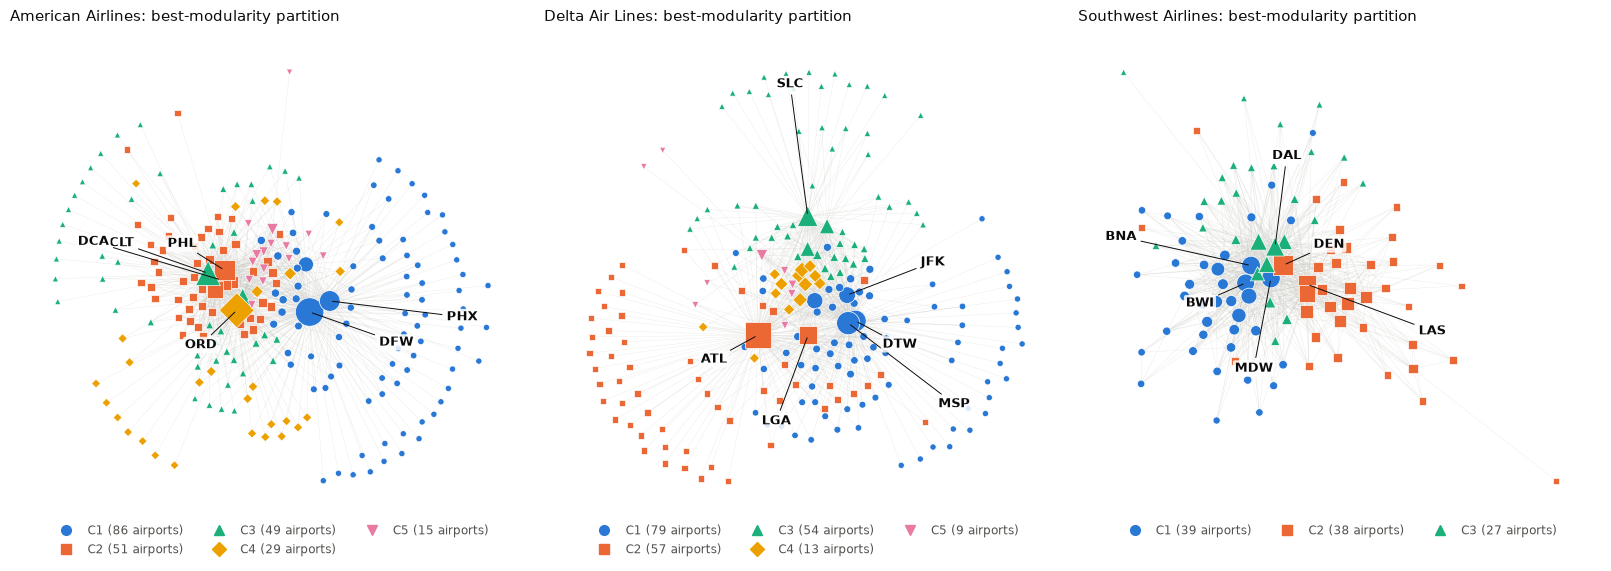

In [20]:
from matplotlib.lines import Line2D

COMMUNITY_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
COMMUNITY_MARKERS = ["o", "s", "^", "D", "v"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5.6), constrained_layout=True)

for ax, airline in zip(axes, AIRLINES):
    U = U_binary[airline]
    order = node_orders[airline]
    labels = dict(zip(order, binary_best[airline]))
    degree = dict(U.degree())
    code_of = dict(zip(airport_tables[airline]["airport_id"], airport_tables[airline]["code"]))
    position = nx.spring_layout(U, seed=42, iterations=200)

    nx.draw_networkx_edges(U, position, ax=ax, width=0.25, edge_color="#c9c8c1", alpha=0.45)

    handles = []

    for community in sorted(set(labels.values())):
        members = [v for v in order if labels[v] == community]
        ax.scatter(
            [position[v][0] for v in members], [position[v][1] for v in members],
            s=[18 + 2.2 * degree[v] for v in members],
            c=COMMUNITY_COLORS[community], marker=COMMUNITY_MARKERS[community],
            edgecolor="white", linewidth=0.5, zorder=3
        )
        handles.append(Line2D(
            [], [], linestyle="", marker=COMMUNITY_MARKERS[community], markersize=7,
            color=COMMUNITY_COLORS[community], label=f"C{community + 1} ({len(members)} airports)"
        ))

    hubs = sorted(order, key=lambda x: -degree[x])[:6]
    centre = np.mean([position[v] for v in hubs], axis=0)

    angle_order = sorted(hubs, key=lambda v: np.arctan2(*(position[v] - centre)[::-1]))

    for index, v in enumerate(angle_order):
        direction = position[v] - centre
        direction = direction / (np.linalg.norm(direction) + 1e-9)
        length = [36, 66, 96][index % 3]
        ax.annotate(code_of[v], position[v], xytext=(length * direction[0], length * direction[1]),
                    textcoords="offset points", fontsize=9, color=INK, fontweight="bold",
                    ha="center", va="center", zorder=5,
                    bbox={"boxstyle": "round,pad=0.15", "facecolor": "white", "edgecolor": "none", "alpha": 0.85},
                    arrowprops={"arrowstyle": "-", "color": INK, "linewidth": 0.7})

    ax.set_title(f"{AIRLINES[airline]}: best-modularity partition", color=INK, fontsize=11, loc="left")
    ax.legend(handles=handles, frameon=False, fontsize=8.5, labelcolor=MUTED, ncol=3,
              loc="upper center", bbox_to_anchor=(0.5, 0.02))
    ax.axis("off")

fig.savefig(FIGURES / "03_community_network_best_partition.png", dpi=300, bbox_inches="tight")
plt.show()

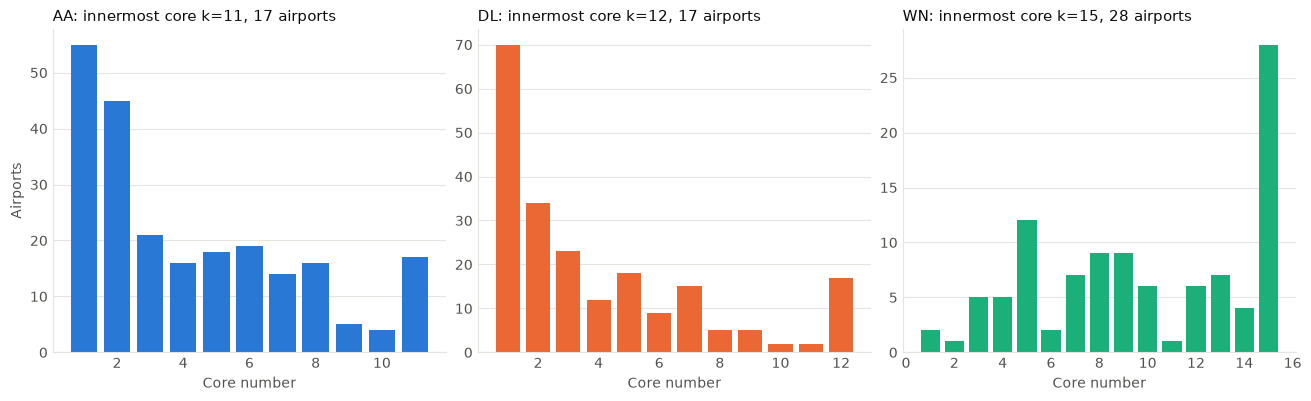

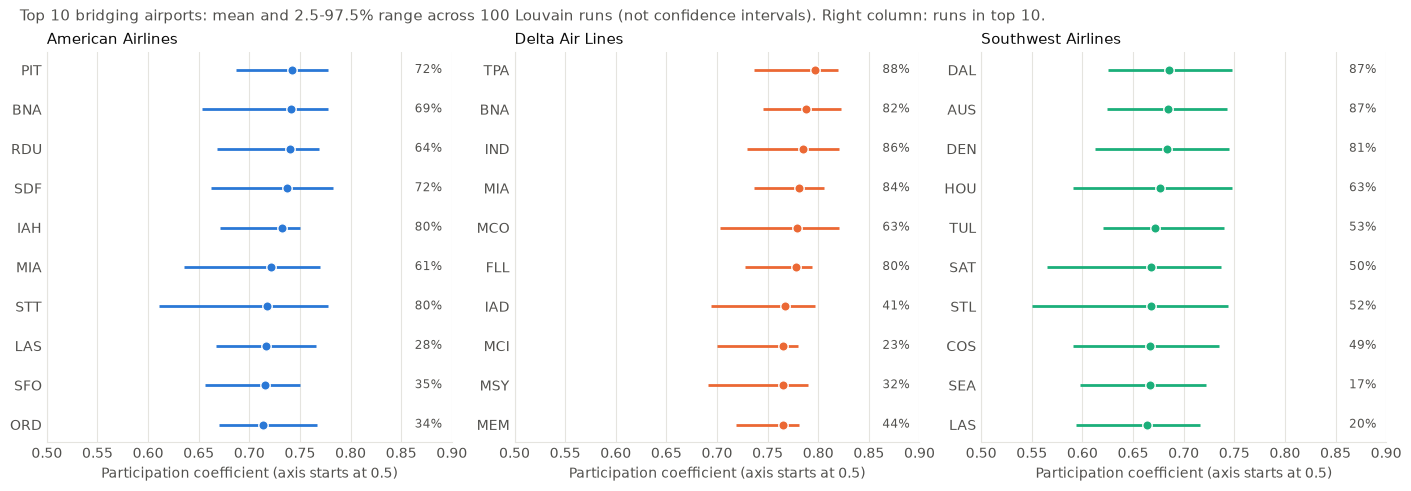

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9), constrained_layout=True)

for ax, airline in zip(axes, AIRLINES):
    shells = kcore_shells_df[kcore_shells_df["Airline"] == airline]
    summary = kcore_summary_df[kcore_summary_df["Airline"] == airline].iloc[0]
    ax.bar(shells["Core number"], shells["Airports"], width=0.8, color=AIRLINE_COLORS[airline])
    ax.set_xlabel("Core number", color=MUTED)
    ax.set_title(
        f"{airline}: innermost core k={int(summary['Maximum core number'])}, {int(summary['Innermost core size'])} airports",
        color=INK, fontsize=11, loc="left"
    )
    style_axis(ax)

axes[0].set_ylabel("Airports", color=MUTED)
fig.savefig(FIGURES / "03_kcore_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), constrained_layout=True)

for ax, airline in zip(axes, AIRLINES):
    top = top_bridging_df[top_bridging_df["Airline"] == airline].sort_values("Participation mean")
    y = np.arange(len(top))
    ax.hlines(y, top["Participation 2.5%"], top["Participation 97.5%"], color=AIRLINE_COLORS[airline], linewidth=2)
    ax.scatter(top["Participation mean"], y, s=46, color=AIRLINE_COLORS[airline], edgecolor="white", linewidth=1, zorder=3)
    ax.set_yticks(y, top["Code"])
    ax.set_xlim(0.5, 0.9)
    ax.set_xlabel("Participation coefficient (axis starts at 0.5)", color=MUTED)
    ax.set_title(f"{AIRLINES[airline]}", color=INK, fontsize=11, loc="left")
    for yi, runs in zip(y, top["Runs in top 10 (%)"]):
        ax.text(0.89, yi, f"{runs:.0f}%", ha="right", va="center", fontsize=8.5, color=MUTED)
    style_axis(ax)
    ax.yaxis.grid(False)
    ax.xaxis.grid(True, color=GRID, linewidth=0.8)

fig.suptitle("Top 10 bridging airports: mean and 2.5-97.5% range across 100 Louvain runs (not confidence intervals). Right column: runs in top 10.",
             color=MUTED, fontsize=10.5, x=0.01, ha="left")
fig.savefig(FIGURES / "03_top_bridging_airports.png", dpi=300, bbox_inches="tight")
plt.show()

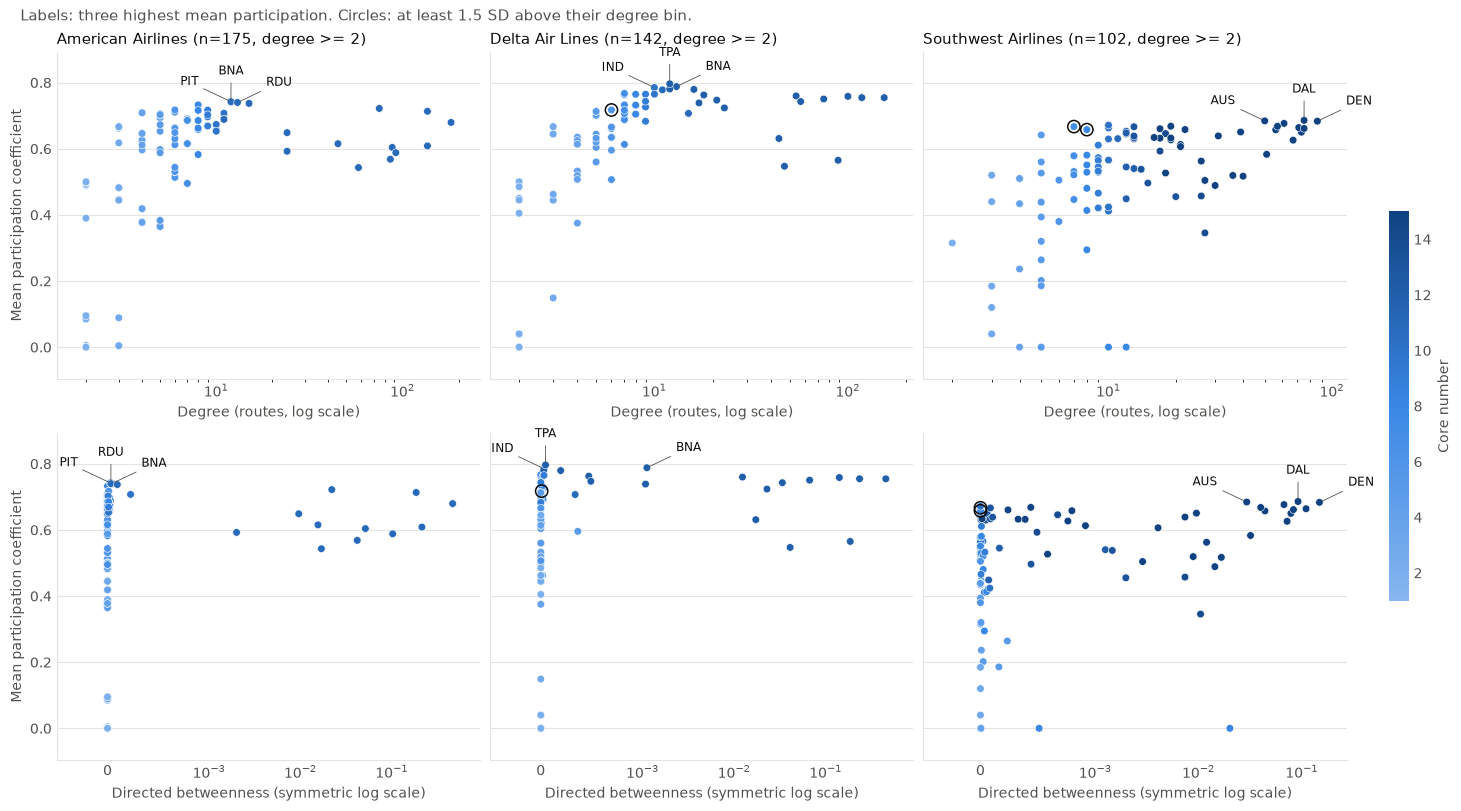

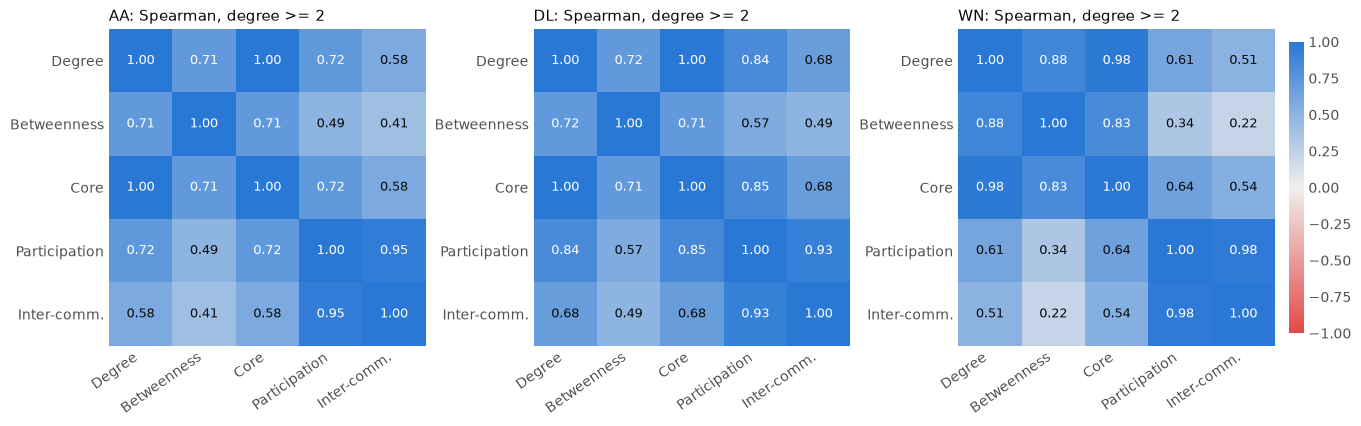

In [22]:
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm, Normalize

core_map = LinearSegmentedColormap.from_list("core", ["#86b6ef", "#3987e5", "#104281"])
core_norm = Normalize(vmin=1, vmax=int(airport_master["Core number"].max()))

fig, axes = plt.subplots(2, 3, figsize=(14.5, 8), constrained_layout=True, sharey=True)

for column, airline in enumerate(AIRLINES):
    table = airport_master[(airport_master["Airline"] == airline) & airport_master["Eligible (degree >= 2)"]]
    label_set = table.nsmallest(3, "Rank by mean Participation")
    flagged = table[table["High for degree"] == True]

    for row, (x_column, xlabel) in enumerate([("Degree", "Degree (routes, log scale)"), ("Betweenness", "Directed betweenness (symmetric log scale)")]):
        ax = axes[row, column]
        scatter = ax.scatter(table[x_column], table["Participation mean"], c=table["Core number"],
                             cmap=core_map, norm=core_norm, s=30, edgecolor="white", linewidth=0.4, zorder=3)
        ax.scatter(flagged[x_column], flagged["Participation mean"], s=78, facecolor="none",
                   edgecolor=INK, linewidth=1.1, zorder=4)
        if x_column == "Degree":
            ax.set_xscale("log")
        else:
            ax.set_xscale("symlog", linthresh=1e-3)
        for (_, point), offset in zip(label_set.sort_values(x_column).iterrows(), [(-30, 12), (0, 20), (30, 12)]):
            ax.annotate(point["Code"], (point[x_column], point["Participation mean"]),
                        xytext=offset, textcoords="offset points", fontsize=8.5, color=INK, ha="center",
                        arrowprops={"arrowstyle": "-", "color": MUTED, "linewidth": 0.6})
        ax.margins(x=0.08, y=0.12)
        if x_column == "Betweenness":
            ax.set_xlim(left=-5e-4)
        ax.set_xlabel(xlabel, color=MUTED)
        if column == 0:
            ax.set_ylabel("Mean participation coefficient", color=MUTED)
        if row == 0:
            ax.set_title(f"{AIRLINES[airline]} (n={len(table)}, degree >= 2)", color=INK, fontsize=11, loc="left")
        style_axis(ax)

colorbar = fig.colorbar(scatter, ax=axes, shrink=0.55, pad=0.012)
colorbar.set_label("Core number", color=MUTED)
colorbar.ax.tick_params(colors=MUTED, length=0)
colorbar.outline.set_visible(False)

fig.suptitle("Labels: three highest mean participation. Circles: at least 1.5 SD above their degree bin.",
             color=MUTED, fontsize=10.5, x=0.01, ha="left")
fig.savefig(FIGURES / "03_degree_betweenness_vs_bridging.png", dpi=300, bbox_inches="tight")
plt.show()

heatmap = LinearSegmentedColormap.from_list("diverging", ["#e34948", "#f0efec", "#2a78d6"])
SHORT_NAMES = ["Degree", "Betweenness", "Core", "Participation", "Inter-comm."]
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.2), constrained_layout=True)

for ax, airline in zip(axes, AIRLINES):
    matrix = airport_master.loc[
        (airport_master["Airline"] == airline) & airport_master["Eligible (degree >= 2)"], MEASURES
    ].corr(method="spearman").to_numpy()
    image = ax.imshow(matrix, cmap=heatmap, norm=TwoSlopeNorm(vmin=-1, vcenter=0, vmax=1))
    ax.set_xticks(range(5), SHORT_NAMES, rotation=35, ha="right", color=MUTED)
    ax.set_yticks(range(5), SHORT_NAMES, color=MUTED)
    ax.tick_params(length=0)
    for i in range(5):
        for j in range(5):
            ax.text(j, i, f"{matrix[i, j]:.2f}", ha="center", va="center", fontsize=9,
                    color="white" if abs(matrix[i, j]) > 0.7 else INK)
    ax.set_title(f"{airline}: Spearman, degree >= 2", color=INK, fontsize=11, loc="left")
    for side in ax.spines.values():
        side.set_visible(False)

colorbar = fig.colorbar(image, ax=axes, shrink=0.8, pad=0.012)
colorbar.ax.tick_params(colors=MUTED, length=0)
colorbar.outline.set_visible(False)
fig.savefig(FIGURES / "03_measure_correlations.png", dpi=300, bbox_inches="tight")
plt.show()

**Validation.** Each check below stops the notebook if it fails, and its result is exported.

In [23]:
validation = []


def check(name, condition, detail=""):
    assert bool(condition), f"FAILED: {name} {detail}"
    validation.append({"Check": name, "Result": "PASS", "Detail": str(detail)})


master = pd.read_csv(TABLES / "03_airport_master.csv")
node_truth = pd.concat([
    t.rename(columns={"airport_id": "AirportID", "code": "CodeTrue", "city": "CityTrue", "state": "StateTrue"}).assign(Airline=a)
    for a, t in airport_tables.items()
], ignore_index=True)
joined = master.merge(node_truth, on=["Airline", "AirportID"], how="outer", validate="one_to_one", indicator=True)

check("Every airport appears in the master table, none added", (joined["_merge"] == "both").all(), len(master))
check("Airport counts match the networks", all((master["Airline"] == a).sum() == G.number_of_nodes() for a, G in graphs.items()))
check("Airport ID and code match the node file", (joined["Code"] == joined["CodeTrue"]).all())
check("City and state match the node file", (joined["City"] == joined["CityTrue"]).all() and (joined["State"] == joined["StateTrue"]).all())
check("No duplicate airport IDs within an airline", not master.duplicated(["Airline", "AirportID"]).any())
check("No duplicate airport codes within an airline", not master.duplicated(["Airline", "Code"]).any())

eligible_flag = master["Eligible (degree >= 2)"].astype(bool)
eligible_only_columns = [
    "Participation average rank across runs", "Runs in top 10", "Runs in top 10 (%)", "Rank by mean Participation",
    "Degree bin", "Bin airports", "Bin assessable", "Excess over bin mean",
    "Runs above bin median (%)", "High for degree"
]
always_required = [c for c in master.columns if c not in eligible_only_columns + ["Within-bin z"]]
check("No missing values in universally required columns", master[always_required].notna().all().all())
check("Eligible airports have every eligible-only field", master.loc[eligible_flag, eligible_only_columns].notna().all().all())
check("Ineligible airports have no eligible-only field", master.loc[~eligible_flag, eligible_only_columns].isna().all().all())
check("Within-bin z exists only for assessable bins", master.loc[master["Bin assessable"] != True, "Within-bin z"].isna().all())
check("Eligibility is exactly degree >= 2", (eligible_flag == (master["Degree"] >= 2)).all())

step2 = pd.read_csv(TABLES / "02_airport_centralities.csv")
step2_join = master.merge(step2, on=["Airline", "AirportID"], suffixes=("", "_s2"), validate="one_to_one")
max_betweenness_difference = float((step2_join["Betweenness"] - step2_join["Betweenness_s2"]).abs().max())
check("Betweenness equals the Step 2 value within CSV floating-point precision", max_betweenness_difference <= 1e-12, f"max abs difference {max_betweenness_difference:.1e}")
check("Degree equals Step 2 in-degree and out-degree", (master["Degree"] == master["In-degree"]).all() and (master["Degree"] == master["Out-degree"]).all())

degree_one = master[master["Degree"] == 1]
check("Degree-1 airports have participation exactly 0 in every run", (degree_one["Participation mean"] == 0).all() and (degree_one["Participation SD"] == 0).all(), len(degree_one))
check("Percentiles are ordered", ((master["Participation 2.5%"] <= master["Participation median"] + 1e-12) & (master["Participation median"] <= master["Participation 97.5%"] + 1e-12)).all())
check("Top-10 counts lie between 0 and 100", master["Runs in top 10"].dropna().between(0, 100).all())

for airline in AIRLINES:
    order = node_orders[airline]
    U, W = U_binary[airline], U_weighted[airline]
    P = P_runs[airline]
    labels = binary_labels[airline]
    communities_per_run = labels.max(axis=1) + 1
    check(f"{airline}: participation stays within 0 and 1-1/C in every run",
          (P >= 0).all() and (P <= 1 - 1 / communities_per_run[:, None] + 1e-12).all())

    # Direct recomputation from neighbour lists, for a run and for the best partition
    for name, row, values, external in [
        ("seed 0", labels[0], P[0], external_runs[airline][0]),
        ("seed 57", labels[57], P[57], external_runs[airline][57]),
    ]:
        label_of = dict(zip(order, row))
        expected_p, expected_e = [], []
        for v in order:
            neighbours = list(U.neighbors(v))
            counts = pd.Series([label_of[u] for u in neighbours]).value_counts()
            expected_p.append(1 - ((counts / len(neighbours)) ** 2).sum())
            expected_e.append(sum(label_of[u] != label_of[v] for u in neighbours) / len(neighbours))
        check(f"{airline}: participation matches neighbour-list calculation ({name})", np.allclose(values, expected_p, atol=1e-12))
        check(f"{airline}: inter-community fraction matches neighbour-list calculation ({name})", np.allclose(external, expected_e, atol=1e-12))

    # Airport-level external fractions aggregate to the network-level fraction in every run
    degrees = np.array([U.degree(v) for v in order], float)
    aggregate = (external_runs[airline] * degrees).sum(axis=1) / degrees.sum()
    network = network_external_runs.loc[network_external_runs["Airline"] == airline, "Inter-community route fraction"].to_numpy()
    check(f"{airline}: airport and network inter-community fractions agree", np.allclose(aggregate, network, atol=1e-12))

    # Weighted participation recomputation
    weighted_row = bridging_weighted[bridging_weighted["Airline"] == airline].set_index("AirportID").loc[order, "Weighted participation mean"].to_numpy()
    adjacency = nx.to_numpy_array(W, nodelist=order, weight="weight", dtype=float)
    direct = np.mean([
        [1 - (pd.Series(adjacency[i]).groupby(row).sum().div(adjacency[i].sum()) ** 2).sum() for i in range(len(order))]
        for row in weighted_labels[airline][:5]
    ], axis=0)
    calculated = np.vstack([participation_and_external(adjacency, row)[0] for row in weighted_labels[airline][:5]]).mean(axis=0)
    check(f"{airline}: weighted participation agrees with direct calculation", np.allclose(direct, calculated, atol=1e-12) and len(weighted_row) == len(order))

    core = core_numbers[airline]
    check(f"{airline}: core number never exceeds degree", all(core[v] <= U.degree(v) for v in U))
    check(f"{airline}: each k-core equals airports with core number >= k",
          all(set(nx.k_core(U, k=k).nodes()) == {v for v in U if core[v] >= k} for k in range(1, max(core.values()) + 1)))
    best_saved = pd.read_csv(TABLES / "03_airport_communities_binary.csv").query("Airline == @airline").set_index("AirportID").loc[order, "Community"].to_numpy()
    check(f"{airline}: best partition labels match the saved Section 3.1 table", np.array_equal(best_saved, binary_best[airline]))

saved_labels = pd.read_csv(TABLES / "03_louvain_run_labels_binary.csv")
check("Saved binary run labels cover 100 seeds per airport with no missing values",
      saved_labels.filter(like="Seed_").shape[1] == 100 and saved_labels.filter(like="Seed_").notna().all().all())

for airline, G in graphs.items():
    check(f"{airline}: original directed weighted network unchanged", network_fingerprint(G) == original_fingerprints[airline])

validation_df = pd.DataFrame(validation)
validation_df.to_csv(TABLES / "03_step3_validation.csv", index=False)

print(f"PASS: {len(validation_df)} validation checks completed.")
display(validation_df.head(14))

PASS: 50 validation checks completed.


,Check,Result,Detail
0,"Every airport appears in the master table, non...",PASS,546
1,Airport counts match the networks,PASS,
2,Airport ID and code match the node file,PASS,
3,City and state match the node file,PASS,
4,No duplicate airport IDs within an airline,PASS,
5,No duplicate airport codes within an airline,PASS,
6,No missing values in universally required columns,PASS,
7,Eligible airports have every eligible-only field,PASS,
8,Ineligible airports have no eligible-only field,PASS,
9,Within-bin z exists only for assessable bins,PASS,


### Step 3 complete

Sections 3.0 to 3.6 are complete. Community membership, core numbers, across-run bridging measures, degree-related comparisons, rankings, figures and validation results have been exported.

**Limitations to carry forward.** Community and bridging measures depend on the Louvain partitions and vary by run; the across-run ranges describe algorithmic variation and are not confidence intervals. Modularity has not yet been compared with degree-preserving null networks. Results depend on the software versions recorded in `03_run_metadata.csv`. The degree-matching bins are sparse for major hubs. All of these measures are observational structural descriptions.

**Not started:** Step 4 null models and all airport-removal experiments.